In [1]:
from platform import python_version
print(python_version())

3.12.4


In [2]:
# Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats

In [3]:
# Load the data
df = pd.read_csv('COVID-19_Report.csv', low_memory=False)

In [4]:
# Display settings
pd.set_option('display.max_columns', None)

In [5]:
# Inspect the data
df

,Contracting Agency ID,Contracting Agency Name,Contracting Office ID,Contracting Office Name,Contracting Office Region,PIID,Modification Number,Unnamed: 7,Transaction Number,Referenced IDV PIID,Date Signed,Unnamed: 11,Period of Performance Start Date,Completion Date,Est. Ultimate Completion Date,Last Date to Order,Funding Department ID,Funding Department Name,Funding Agency ID,Funding Office ID,Foreign Funding,Domestic or Foreign Entity,Is Performance Based Service Acquisition,Type of Contract,Product or Service Code,Product or Service Description,Description of Requirement,Inherently Governmental Function,NAICS Code,NAICS Description,Principal Place of Performance County Name,Principal Place of Performance Location Code,Principal Place of Performance Location Name,Principal Place of Performance State Code,Principal Place of Performance Congressional District,Principal Place of Performance Zip Code,Principal Place of Performance Country Name,Country of Product or Service Origin,Place of Manufacture,Extent Competed,Source Selection Process,Other Than Full and Open Competition,Solicitation Procedures,Solicitation Date,Type of Set Aside,IDV Type of Set Aside,Type of Set Aside Source,Local Area Set Aside,Evaluated Preference,SBIR/STTR,Fair Opportunity/Limited Sources,Commercial Products/Services Acquisition Procedures,Award Type,Reason For Modification,Unique Entity ID,Legal Business Name,Ultimate Parent Unique Entity ID,Ultimate Parent Legal Business Name,Vendor Address Line 1,Vendor Address Line 2,Vendor Address City,Vendor Address State Name,Vendor Address Zip Code,Vendor Address Country Name,FAR 4.1102 Exception Type,Vendor Congressional District,Is Vendor Business Type - Contracts,Is Vendor Business Type - Federal Assistance Awards,Is Vendor Business Type - All Awards,Is Vendor Business Type - U.S. Federal Government,Is Vendor Business Type - Federally Funded Research and Development Corporation,Is Vendor Business Type - Federal Agency,Is Vendor Business Type - U.S. State Government,Is Vendor Business Type - U.S. Local Government,Is Vendor Business Type - City,Is Vendor Business Type - County,Is Vendor Business Type - Inter Municipal,Is Vendor Business Type - Local Government Owned,Is Vendor Business Type - Municipality,Is Vendor Business Type - School District,Is Vendor Business Type - Township,Is Vendor Business Type - U.S. Tribal Government,Is Vendor Business Type - Foreign Government,Is Vendor Business Type - Airport Authority,Is Vendor Business Type - Council Of Governments,Is Vendor Business Type - Housing Authorities Public or Tribal,Is Vendor Business Type - Interstate Entity,Is Vendor Business Type - Planning Commission,Is Vendor Business Type - Port Authority,Is Vendor Business Type - Transit Authority,"Is Vendor Business Type - Corporate Entity, Not Tax Exempt","Is Vendor Business Type - Corporate Entity, Tax Exempt",Is Vendor Business Type - Subchapter S Corporation,Is Vendor Business Type - Limited Liability Corporation,Is Vendor Business Type - Partnership or Limited Liability Partnership,Is Vendor Business Type - Sole Proprietorship,Is Vendor Business Type - Small Agricultural Cooperative,Is Vendor Business Type - International Organization,Is Vendor Business Type - U.S. Government Entity,Is Vendor Business Type - Foreign Owned,Is Vendor Business Type - For Profit Organization,Is Vendor Business Type - Non Profit Organization,Is Vendor Business Type - Other Not For Profit Organization,Is Vendor Business Type - Community Development Corporation-Owned Concern,Is Vendor Business Type - Labor Surplus Area Firm,Is Vendor Business Type - Self-Certified Small Disadvantaged Business,Is Vendor Business Type - Veteran-Owned Business,Is Vendor Business Type - Service-Disabled Veteran-Owned Business,Is Vendor Business Type - Women-Owned Business,Is Vendor Business Type - Women-Owned Small Business,Is Vendor Business Type - Economically Disadvantaged Women-Owned Small Business,Is Vendor Business Type - Women-Owned Small Bus

In [6]:
# Inspect the data
df.shape

(150000, 176)

In [7]:
df.columns

Index(['Contracting Agency ID', 'Contracting Agency Name',
       'Contracting Office ID', 'Contracting Office Name',
       'Contracting Office Region', 'PIID', 'Modification Number',
       'Unnamed: 7', 'Transaction Number', 'Referenced IDV PIID',
       ...
       'Interagency Contracting Authority', 'National Interest Action',
       'Treasury Account Symbol Initiative',
       'Treasury Account Symbol Agency Identifier',
       'Treasury Account Symbol Main Account',
       'Treasury Account Symbol Sub Account', 'Number of Actions',
       'Action Obligation', 'Base and Exercised Options Value',
       'Base and All Options Value (Total Contract Value)'],
      dtype='object', length=176)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Columns: 176 entries, Contracting Agency ID to Base and All Options Value (Total Contract Value)
dtypes: float64(9), int64(1), object(166)
memory usage: 201.4+ MB


In [9]:
df.head()

,Contracting Agency ID,Contracting Agency Name,Contracting Office ID,Contracting Office Name,Contracting Office Region,PIID,Modification Number,Unnamed: 7,Transaction Number,Referenced IDV PIID,Date Signed,Unnamed: 11,Period of Performance Start Date,Completion Date,Est. Ultimate Completion Date,Last Date to Order,Funding Department ID,Funding Department Name,Funding Agency ID,Funding Office ID,Foreign Funding,Domestic or Foreign Entity,Is Performance Based Service Acquisition,Type of Contract,Product or Service Code,Product or Service Description,Description of Requirement,Inherently Governmental Function,NAICS Code,NAICS Description,Principal Place of Performance County Name,Principal Place of Performance Location Code,Principal Place of Performance Location Name,Principal Place of Performance State Code,Principal Place of Performance Congressional District,Principal Place of Performance Zip Code,Principal Place of Performance Country Name,Country of Product or Service Origin,Place of Manufacture,Extent Competed,Source Selection Process,Other Than Full and Open Competition,Solicitation Procedures,Solicitation Date,Type of Set Aside,IDV Type of Set Aside,Type of Set Aside Source,Local Area Set Aside,Evaluated Preference,SBIR/STTR,Fair Opportunity/Limited Sources,Commercial Products/Services Acquisition Procedures,Award Type,Reason For Modification,Unique Entity ID,Legal Business Name,Ultimate Parent Unique Entity ID,Ultimate Parent Legal Business Name,Vendor Address Line 1,Vendor Address Line 2,Vendor Address City,Vendor Address State Name,Vendor Address Zip Code,Vendor Address Country Name,FAR 4.1102 Exception Type,Vendor Congressional District,Is Vendor Business Type - Contracts,Is Vendor Business Type - Federal Assistance Awards,Is Vendor Business Type - All Awards,Is Vendor Business Type - U.S. Federal Government,Is Vendor Business Type - Federally Funded Research and Development Corporation,Is Vendor Business Type - Federal Agency,Is Vendor Business Type - U.S. State Government,Is Vendor Business Type - U.S. Local Government,Is Vendor Business Type - City,Is Vendor Business Type - County,Is Vendor Business Type - Inter Municipal,Is Vendor Business Type - Local Government Owned,Is Vendor Business Type - Municipality,Is Vendor Business Type - School District,Is Vendor Business Type - Township,Is Vendor Business Type - U.S. Tribal Government,Is Vendor Business Type - Foreign Government,Is Vendor Business Type - Airport Authority,Is Vendor Business Type - Council Of Governments,Is Vendor Business Type - Housing Authorities Public or Tribal,Is Vendor Business Type - Interstate Entity,Is Vendor Business Type - Planning Commission,Is Vendor Business Type - Port Authority,Is Vendor Business Type - Transit Authority,"Is Vendor Business Type - Corporate Entity, Not Tax Exempt","Is Vendor Business Type - Corporate Entity, Tax Exempt",Is Vendor Business Type - Subchapter S Corporation,Is Vendor Business Type - Limited Liability Corporation,Is Vendor Business Type - Partnership or Limited Liability Partnership,Is Vendor Business Type - Sole Proprietorship,Is Vendor Business Type - Small Agricultural Cooperative,Is Vendor Business Type - International Organization,Is Vendor Business Type - U.S. Government Entity,Is Vendor Business Type - Foreign Owned,Is Vendor Business Type - For Profit Organization,Is Vendor Business Type - Non Profit Organization,Is Vendor Business Type - Other Not For Profit Organization,Is Vendor Business Type - Community Development Corporation-Owned Concern,Is Vendor Business Type - Labor Surplus Area Firm,Is Vendor Business Type - Self-Certified Small Disadvantaged Business,Is Vendor Business Type - Veteran-Owned Business,Is Vendor Business Type - Service-Disabled Veteran-Owned Business,Is Vendor Business Type - Women-Owned Business,Is Vendor Business Type - Women-Owned Small Business,Is Vendor Business Type - Economically Disadvantaged Women-Owned Small Business,Is Vendor Business Type - Women-Owned Small Bus

In [10]:
# Check for duplicates

exact_duplicate_count = df.duplicated().sum()

print(f"Exact duplicate rows: {exact_duplicate_count:,}")
print(
    f"Percentage: "
    f"{exact_duplicate_count / len(df) * 100:.4f}%"
)

Exact duplicate rows: 0
Percentage: 0.0000%


In [11]:
# Remove Duplicates 
df = df.drop_duplicates()

In [12]:
# Check to see how many removed
df.shape

(150000, 176)

In [13]:
# Check for PIID and modification number to confirm no duplicate records

[
    col for col in df.columns
    if 'piid' in col.lower() or 'modification' in col.lower()
]

['PIID',
 'Modification Number',
 'Referenced IDV PIID',
 'Reason For Modification']

In [14]:
# Check missing and unique in PIID and Modification Number

id_columns = ['PIID', 'Modification Number']

for col in id_columns:
    print(f"\n{col}")
    print("-" * 50)
    print(f"Missing: {df[col].isna().sum():,}")
    print(f"Unique:  {df[col].nunique(dropna=True):,}")


PIID
--------------------------------------------------
Missing: 0
Unique:  111,723

Modification Number
--------------------------------------------------
Missing: 0
Unique:  1,106


In [15]:
# Check duplicate PIID and Modification Number combinations

key_columns = ['PIID', 'Modification Number']

duplicate_key_mask = df.duplicated(
    subset=key_columns,
    keep=False
)

duplicate_key_records = df.loc[
    duplicate_key_mask
].copy()

print(
    f"Rows involved in duplicate PIID + Modification Number "
    f"combinations: {duplicate_key_mask.sum():,}"
)

Rows involved in duplicate PIID + Modification Number combinations: 1,114


In [16]:
# Examine Transaction Number

print("Transaction Number diagnostics")
print("-" * 50)

print(
    f"Missing: "
    f"{df['Transaction Number'].isna().sum():,}"
)

print(
    f"Unique: "
    f"{df['Transaction Number'].nunique(dropna=True):,}"
)

print("\nMost frequent values:")
print(
    df['Transaction Number']
    .value_counts(dropna=False)
    .head(20)
)

Transaction Number diagnostics
--------------------------------------------------
Missing: 5,288
Unique: 12

Most frequent values:
Transaction Number
0.0     143420
NaN       5288
1.0        718
4.0        198
6.0        140
2.0        128
14.0        46
16.0        34
10.0        14
5.0          7
3.0          4
17.0         2
9.0          1
Name: count, dtype: int64


In [17]:
# Calculate duplicate combinations

duplicate_key_groups = (
    duplicate_key_records
    .groupby(key_columns, dropna=False)
    .size()
    .reset_index(name='Record Count')
    .sort_values('Record Count', ascending=False)
)

print(
    f"Duplicate PIID + Modification Number combinations: "
    f"{len(duplicate_key_groups):,}"
)

duplicate_key_groups.head(20)

Duplicate PIID + Modification Number combinations: 373


,PIID,Modification Number,Record Count
343,75R60222F34001,0,16
344,75R60222F34002,0,16
188,75N93020F00001,0,15
257,75N93022F00001,0,12
332,75R60221F34001,0,11
311,75N98021F00002,0,10
189,75N93020F00001,P00001,10
345,75R60222F34003,0,9
190,75N93020F00001,P00002,9
100,75FCMC20F0001,P00001,9


In [18]:
# Determine if records are actually identical 

group_diagnostics = (
    duplicate_key_records
    .groupby(key_columns, dropna=False)
    .apply(
        lambda x: pd.Series({
            'Record Count': len(x),
            'Unique Full Rows': len(x.drop_duplicates())
        }),
        include_groups=False
    )
    .reset_index()
)

group_diagnostics['Exact Within-Key Duplicates'] = (
    group_diagnostics['Record Count']
    - group_diagnostics['Unique Full Rows']
)

group_diagnostics.sort_values(
    ['Record Count', 'Unique Full Rows'],
    ascending=False
).head(20)

,PIID,Modification Number,Record Count,Unique Full Rows,Exact Within-Key Duplicates
343,75R60222F34001,0,16,16,0
344,75R60222F34002,0,16,16,0
188,75N93020F00001,0,15,15,0
257,75N93022F00001,0,12,12,0
332,75R60221F34001,0,11,11,0
189,75N93020F00001,P00001,10,10,0
311,75N98021F00002,0,10,10,0
100,75FCMC20F0001,P00001,9,9,0
190,75N93020F00001,P00002,9,9,0
345,75R60222F34003,0,9,9,0


In [19]:
# Find candidate identified fields

identifier_candidates = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        'id',
        'number',
        'transaction',
        'action'
    ])
]

identifier_candidates

['Contracting Agency ID',
 'Contracting Office ID',
 'PIID',
 'Modification Number',
 'Transaction Number',
 'Referenced IDV PIID',
 'Funding Department ID',
 'Funding Agency ID',
 'Funding Office ID',
 'Type of Set Aside',
 'IDV Type of Set Aside',
 'Type of Set Aside Source',
 'Local Area Set Aside',
 'Unique Entity ID',
 'Ultimate Parent Unique Entity ID',
 'National Interest Action',
 'Treasury Account Symbol Agency Identifier',
 'Number of Actions',
 'Action Obligation']

In [20]:
# Inspect one example group 

example_group = df[
    (df['PIID'] == '75R60222F34001') &
    (df['Modification Number'].astype(str) == '0')
].copy()

print(f"Records in group: {len(example_group)}")

columns_to_view = [
    'PIID',
    'Modification Number',
    'Referenced IDV PIID',
    'Reason For Modification',
    'Date Signed',
    'Action Obligation',
    'Base and All Options Value (Total Contract Value)',
    'Award Type',
    'Contracting Office Name',
    'Funding Department Name',
    'NAICS Code',
    'Product or Service Code'
]

example_group[
    [c for c in columns_to_view if c in df.columns]
]

Records in group: 16


,PIID,Modification Number,Referenced IDV PIID,Reason For Modification,Date Signed,Action Obligation,Base and All Options Value (Total Contract Value),Award Type,Contracting Office Name,Funding Department Name,NAICS Code,Product or Service Code
89522,75R60222F34001,0,75R60222A00003,NaN,2/15/2022,"$6,250.00","$6,250.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",541611,R424
89523,75R60222F34001,0,75R60222A00004,NaN,2/15/2022,"$8,750.00","$8,750.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",541611,R424
89524,75R60222F34001,0,75R60222A00005,NaN,2/15/2022,"$6,250.00","$6,250.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",541611,R424
89525,75R60222F34001,0,75R60222A00006,NaN,2/15/2022,"$8,750.00","$8,750.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",541611,R424
89526,75R60222F34001,0,75R60222A00009,NaN,2/16/2022,"$9,850.00","$9,850.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",541611,R424
89527,75R60222F34001,0,75R60222A00010,NaN,2/26/2022,"$6,250.00","$6,250.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",621111,R424
89528,75R60222F34001,0,75R60222A00011,NaN,3/29/2022,"$8,750.00","$8,750.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",541611,R424
89529,75R60222F34001,0,75R60222A00014,NaN,3/28/2022,"$8,750.00","$8,750.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",541611,R424
89530,75R60222F34001,0,75R60222A00015,NaN,3/29/2022,"$8,750.00","$8,750.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",541611,R424
89531,75R60222F34001,0,75R60222A00016,NaN,3/28/2022,"$8,750.00","$8,750.00",BPA CALL,HRSA HEADQUARTERS,"HEALTH AND HUMAN SERVICES, DEPARTMENT OF",541611,R424


In [21]:
# Identify which columns vary among the 16 records

varying_columns = [
    col for col in example_group.columns
    if example_group[col].nunique(dropna=False) > 1
]

print(f"Columns that vary within the group: {len(varying_columns)}")

varying_columns

Columns that vary within the group: 42


['Referenced IDV PIID',
 'Date Signed',
 'Period of Performance Start Date',
 'Completion Date',
 'Est. Ultimate Completion Date',
 'Description of Requirement',
 'NAICS Code',
 'NAICS Description',
 'Principal Place of Performance County Name',
 'Principal Place of Performance Location Name',
 'Principal Place of Performance State Code',
 'Principal Place of Performance Congressional District',
 'Principal Place of Performance Zip Code',
 'Type of Set Aside',
 'Commercial Products/Services Acquisition Procedures',
 'Unique Entity ID',
 'Legal Business Name',
 'Ultimate Parent Unique Entity ID',
 'Ultimate Parent Legal Business Name',
 'Vendor Address Line 1',
 'Vendor Address City',
 'Vendor Address State Name',
 'Vendor Address Zip Code',
 'Vendor Congressional District',
 'Is Vendor Business Type - Corporate Entity, Not Tax Exempt',
 'Is Vendor Business Type - Limited Liability Corporation',
 'Is Vendor Business Type - Sole Proprietorship',
 'Is Vendor Business Type - Self-Certified

In [22]:
# Create a set of fields that meaningfully distingish records

distinguishing_fields = [
    'Date Signed',
    'Referenced IDV PIID',
    'Unique Entity ID',
    'Legal Business Name',
    'NAICS Code',
    'Product or Service Code',
    'Description of Requirement',
    'Action Obligation',
    'Base and All Options Value (Total Contract Value)'
]

In [23]:
# Calculate how many distinguishing fields vary within each repeated PIID/Mod group

group_variation = (
    duplicate_key_records
    .groupby(
        ['PIID', 'Modification Number'],
        dropna=False
    )[distinguishing_fields]
    .nunique(dropna=False)
)

# Number of substantive fields that vary within each group
group_variation['Fields That Vary'] = (
    group_variation > 1
).sum(axis=1)

print(
    "Repeated PIID/Modification groups examined:",
    f"{len(group_variation):,}"
)

print(
    "Groups with at least one substantive difference:",
    f"{(group_variation['Fields That Vary'] > 0).sum():,}"
)

print(
    "Groups with no differences in these fields:",
    f"{(group_variation['Fields That Vary'] == 0).sum():,}"
)

print("\nDistribution of number of fields that vary:")
print(
    group_variation['Fields That Vary']
    .value_counts()
    .sort_index()
)

Repeated PIID/Modification groups examined: 373
Groups with at least one substantive difference: 369
Groups with no differences in these fields: 4

Distribution of number of fields that vary:
Fields That Vary
0      4
1      6
2      7
3      3
4      1
5      8
6     22
7     50
8     39
9    233
Name: count, dtype: int64


In [24]:
# Determine which attributed most frequently distinguish the repeated combinations

field_variation_summary = pd.DataFrame({
    'Field': distinguishing_fields,
    'Groups Where Field Varies': [
        (group_variation[field] > 1).sum()
        for field in distinguishing_fields
    ]
})

field_variation_summary['Percent of Repeated Groups'] = (
    field_variation_summary['Groups Where Field Varies']
    / len(group_variation)
    * 100
)

field_variation_summary = (
    field_variation_summary
    .sort_values(
        'Groups Where Field Varies',
        ascending=False
    )
    .reset_index(drop=True)
)

field_variation_summary

,Field,Groups Where Field Varies,Percent of Repeated Groups
0,Description of Requirement,354,94.906166
1,Referenced IDV PIID,353,94.638070
2,Date Signed,346,92.761394
3,Unique Entity ID,343,91.957105
4,Legal Business Name,343,91.957105
5,Action Obligation,337,90.348525
6,Base and All Options Value (Total Contract Value),323,86.595174
7,NAICS Code,284,76.139410
8,Product or Service Code,281,75.335121


In [25]:
# Isolate potentially concerning records

no_variation_keys = (
    group_variation[
        group_variation['Fields That Vary'] == 0
    ]
    .reset_index()[
        ['PIID', 'Modification Number']
    ]
)

potential_duplicate_records = (
    duplicate_key_records
    .merge(
        no_variation_keys,
        on=['PIID', 'Modification Number'],
        how='inner'
    )
)

print(
    "Records requiring closer inspection:",
    f"{len(potential_duplicate_records):,}"
)

potential_duplicate_records.head()

Records requiring closer inspection: 9


,Contracting Agency ID,Contracting Agency Name,Contracting Office ID,Contracting Office Name,Contracting Office Region,PIID,Modification Number,Unnamed: 7,Transaction Number,Referenced IDV PIID,Date Signed,Unnamed: 11,Period of Performance Start Date,Completion Date,Est. Ultimate Completion Date,Last Date to Order,Funding Department ID,Funding Department Name,Funding Agency ID,Funding Office ID,Foreign Funding,Domestic or Foreign Entity,Is Performance Based Service Acquisition,Type of Contract,Product or Service Code,Product or Service Description,Description of Requirement,Inherently Governmental Function,NAICS Code,NAICS Description,Principal Place of Performance County Name,Principal Place of Performance Location Code,Principal Place of Performance Location Name,Principal Place of Performance State Code,Principal Place of Performance Congressional District,Principal Place of Performance Zip Code,Principal Place of Performance Country Name,Country of Product or Service Origin,Place of Manufacture,Extent Competed,Source Selection Process,Other Than Full and Open Competition,Solicitation Procedures,Solicitation Date,Type of Set Aside,IDV Type of Set Aside,Type of Set Aside Source,Local Area Set Aside,Evaluated Preference,SBIR/STTR,Fair Opportunity/Limited Sources,Commercial Products/Services Acquisition Procedures,Award Type,Reason For Modification,Unique Entity ID,Legal Business Name,Ultimate Parent Unique Entity ID,Ultimate Parent Legal Business Name,Vendor Address Line 1,Vendor Address Line 2,Vendor Address City,Vendor Address State Name,Vendor Address Zip Code,Vendor Address Country Name,FAR 4.1102 Exception Type,Vendor Congressional District,Is Vendor Business Type - Contracts,Is Vendor Business Type - Federal Assistance Awards,Is Vendor Business Type - All Awards,Is Vendor Business Type - U.S. Federal Government,Is Vendor Business Type - Federally Funded Research and Development Corporation,Is Vendor Business Type - Federal Agency,Is Vendor Business Type - U.S. State Government,Is Vendor Business Type - U.S. Local Government,Is Vendor Business Type - City,Is Vendor Business Type - County,Is Vendor Business Type - Inter Municipal,Is Vendor Business Type - Local Government Owned,Is Vendor Business Type - Municipality,Is Vendor Business Type - School District,Is Vendor Business Type - Township,Is Vendor Business Type - U.S. Tribal Government,Is Vendor Business Type - Foreign Government,Is Vendor Business Type - Airport Authority,Is Vendor Business Type - Council Of Governments,Is Vendor Business Type - Housing Authorities Public or Tribal,Is Vendor Business Type - Interstate Entity,Is Vendor Business Type - Planning Commission,Is Vendor Business Type - Port Authority,Is Vendor Business Type - Transit Authority,"Is Vendor Business Type - Corporate Entity, Not Tax Exempt","Is Vendor Business Type - Corporate Entity, Tax Exempt",Is Vendor Business Type - Subchapter S Corporation,Is Vendor Business Type - Limited Liability Corporation,Is Vendor Business Type - Partnership or Limited Liability Partnership,Is Vendor Business Type - Sole Proprietorship,Is Vendor Business Type - Small Agricultural Cooperative,Is Vendor Business Type - International Organization,Is Vendor Business Type - U.S. Government Entity,Is Vendor Business Type - Foreign Owned,Is Vendor Business Type - For Profit Organization,Is Vendor Business Type - Non Profit Organization,Is Vendor Business Type - Other Not For Profit Organization,Is Vendor Business Type - Community Development Corporation-Owned Concern,Is Vendor Business Type - Labor Surplus Area Firm,Is Vendor Business Type - Self-Certified Small Disadvantaged Business,Is Vendor Business Type - Veteran-Owned Business,Is Vendor Business Type - Service-Disabled Veteran-Owned Business,Is Vendor Business Type - Women-Owned Business,Is Vendor Business Type - Women-Owned Small Business,Is Vendor Business Type - Economically Disadvantaged Women-Owned Small Business,Is Vendor Business Type - Women-Owned Small Bus

In [26]:
# Identify every column that varies within each of the 4 groups

for _, row in no_variation_keys.iterrows():

    piid = row['PIID']
    mod = row['Modification Number']

    group = df[
        (df['PIID'] == piid) &
        (df['Modification Number'] == mod)
    ]

    varying = [
        col for col in df.columns
        if group[col].nunique(dropna=False) > 1
    ]

    print("=" * 80)
    print(f"PIID: {piid}")
    print(f"Modification Number: {mod}")
    print(f"Records: {len(group)}")
    print(f"Fields that vary: {len(varying)}")
    print("\nVarying fields:")
    print(varying)
    print()

PIID: H9222213C0053
Modification Number: P00078
Records: 2
Fields that vary: 2

Varying fields:
['Transaction Number', 'Type of Contract']

PIID: N0001915C0092
Modification Number: P00062
Records: 2
Fields that vary: 5

Varying fields:
['Transaction Number', 'Completion Date', 'Est. Ultimate Completion Date', 'Treasury Account Symbol Agency Identifier', 'Treasury Account Symbol Main Account']

PIID: N0001916C0036
Modification Number: P00017
Records: 3
Fields that vary: 8

Varying fields:
['Transaction Number', 'Completion Date', 'Est. Ultimate Completion Date', 'Type of Contract', 'Principal Place of Performance Zip Code', 'Vendor Address Zip Code', 'Treasury Account Symbol Agency Identifier', 'Treasury Account Symbol Main Account']

PIID: W15QKN16C0095
Modification Number: P00004
Records: 2
Fields that vary: 5

Varying fields:
['Transaction Number', 'Funding Office ID', 'Foreign Funding', 'Treasury Account Symbol Agency Identifier', 'Treasury Account Symbol Main Account']



In [27]:
# Create basic summary table of missing data
missing_summary = pd.DataFrame({
    'Variable': df.columns,
    'Data Type': df.dtypes.values,
    'Missing Count': df.isnull().sum().values,
    'Percent Missing': (df.isnull().sum() / len(df) * 100).round(2).values
})

# Sort by percent missing (highest first)
missing_summary = missing_summary.sort_values(
    by='Percent Missing',
    ascending=False
)

# Display
print(missing_summary)

# Optional: save to Excel
missing_summary.to_excel('variable_missingness_summary.xlsx', index=False)

                                              Variable Data Type  \
168                 Treasury Account Symbol Initiative    object   
7                                           Unnamed: 7   float64   
11                                         Unnamed: 11   float64   
31        Principal Place of Performance Location Code   float64   
155  Is Vendor Business Type - Small Business Joint...    object   
..                                                 ...       ...   
81    Is Vendor Business Type - U.S. Tribal Government    object   
73     Is Vendor Business Type - U.S. Local Government    object   
72     Is Vendor Business Type - U.S. State Government    object   
69   Is Vendor Business Type - U.S. Federal Government    object   
175  Base and All Options Value (Total Contract Value)    object   

     Missing Count  Percent Missing  
168         149998            100.0  
7           150000            100.0  
11          150000            100.0  
31          150000            1

In [28]:
# Assess variables that are nearly missing, IDs, or constants

summary = pd.DataFrame({
    'Variable': df.columns,
    'Data Type': df.dtypes.values,
    'Missing Count': df.isnull().sum().values,
    'Percent Missing': (df.isnull().sum()/len(df)*100).round(2).values,
    'Unique Values': df.nunique(dropna=True).values
})

summary = summary.sort_values(
    by=['Percent Missing'],
    ascending=False
)

summary.head()

,Variable,Data Type,Missing Count,Percent Missing,Unique Values
168,Treasury Account Symbol Initiative,object,149998,100.0,1
7,Unnamed: 7,float64,150000,100.0,0
11,Unnamed: 11,float64,150000,100.0,0
31,Principal Place of Performance Location Code,float64,150000,100.0,0
155,Is Vendor Business Type - Small Business Joint...,object,149405,99.6,1


In [29]:
# Separate variables by type

# Numeric variables
numeric_vars = df.select_dtypes(include=['number']).columns.tolist()

# Categorical/object variables
categorical_vars = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Date variables (if already parsed)
date_vars = df.select_dtypes(include=['datetime64[ns]']).columns.tolist()

print(f"Numeric variables: {len(numeric_vars)}")
print(f"Categorical variables: {len(categorical_vars)}")
print(f"Date variables: {len(date_vars)}")

Numeric variables: 10
Categorical variables: 166
Date variables: 0


In [30]:
# Export Data Dictionary in Excel and display first 5 rows

# Create data dictionary summary
data_dictionary = pd.DataFrame({
    'Variable': df.columns,
    'Data_Type': df.dtypes.astype(str).values,
    'Missing_Count': df.isnull().sum().values,
    'Percent_Missing': (
        df.isnull().sum() / len(df) * 100
    ).round(2).values,
    'Unique_Values': df.nunique(dropna=True).values
})

# Add non-missing count
data_dictionary['Non_Missing_Count'] = (
    len(df) - data_dictionary['Missing_Count']
)

# Add percent unique
data_dictionary['Percent_Unique'] = (
    data_dictionary['Unique_Values'] / len(df) * 100
).round(2)

# Sort by missingness
data_dictionary = data_dictionary.sort_values(
    by='Percent_Missing',
    ascending=False
)

# Reorder columns 
data_dictionary = data_dictionary[
    [
        'Variable',
        'Data_Type',
        'Non_Missing_Count',
        'Missing_Count',
        'Percent_Missing',
        'Unique_Values',
        'Percent_Unique'
    ]
]

# Export to Excel
data_dictionary.to_excel(
    'Data_Dictionary_Summary.xlsx',
    index=False
)

# Display first 5 rows
print(data_dictionary.head())

                                              Variable Data_Type  \
168                 Treasury Account Symbol Initiative    object   
7                                           Unnamed: 7   float64   
11                                         Unnamed: 11   float64   
31        Principal Place of Performance Location Code   float64   
155  Is Vendor Business Type - Small Business Joint...    object   

     Non_Missing_Count  Missing_Count  Percent_Missing  Unique_Values  \
168                  2         149998            100.0              1   
7                    0         150000            100.0              0   
11                   0         150000            100.0              0   
31                   0         150000            100.0              0   
155                595         149405             99.6              1   

     Percent_Unique  
168             0.0  
7               0.0  
11              0.0  
31              0.0  
155             0.0  


In [31]:
# Percent Missing by Variable

selected_variables = ['Other Than Full and Open Competition', 
                        'Fair Opportunity/Limited Sources', 
                        'Type of Set Aside', 
                        'Solicitation Date', 
                        'Completion Date', 
                        'Domestic or Foreign Entity', 
                        'Vendor Address State Name', 
                        'Solicitation Procedures', 
                        'Extent Competed', 
                        'Description of Requirement', 
                        'Action Obligation', 
                        "Contracting Officer's Business Size Determination", 
                        'NAICS Code', 
                        'Product or Service Description', 
                        'Product or Service Code', 
                        'Type of Contract', 
                        'Funding Department Name', 
                        'Period of Performance Start Date', 
                        'Date Signed', 
                        'Contracting Office Name', 
                        'Award Type', 
                        'Base and All Options Value (Total Contract Value)']

missing_pct = (
    df[selected_variables]
    .isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(missing_pct)

Other Than Full and Open Competition                 76.797333
Fair Opportunity/Limited Sources                     71.863333
Type of Set Aside                                    66.692000
Solicitation Date                                    57.892000
Completion Date                                       3.525333
Domestic or Foreign Entity                            3.382000
Vendor Address State Name                             1.257333
Solicitation Procedures                               0.966667
Extent Competed                                       0.913333
Description of Requirement                            0.014667
Period of Performance Start Date                      0.002000
Funding Department Name                               0.000000
Award Type                                            0.000000
Contracting Office Name                               0.000000
Date Signed                                           0.000000
Contracting Officer's Business Size Determination     0

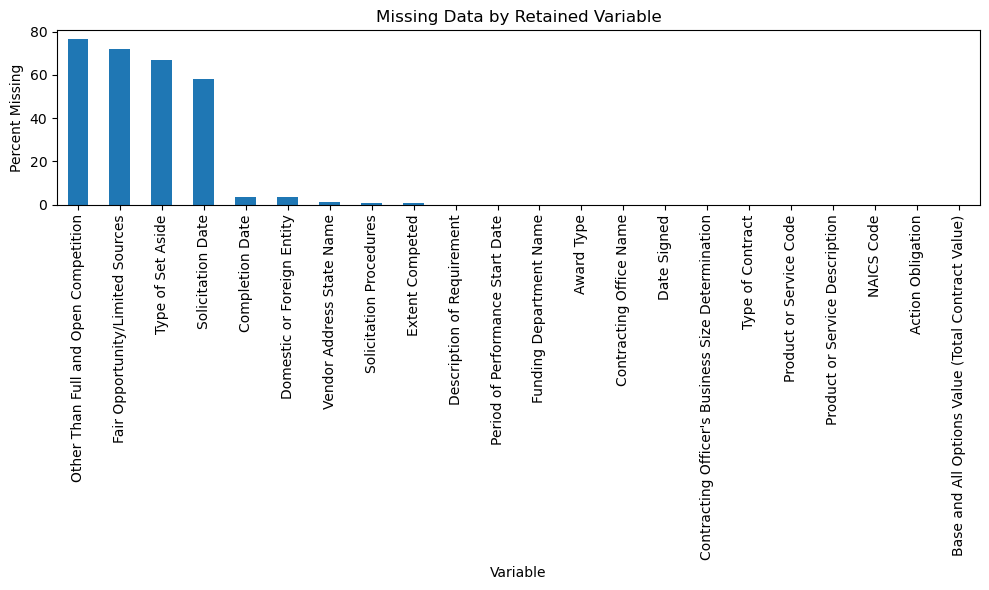

In [32]:
# Visualize Missingness

plt.figure(figsize=(10,6))
missing_pct.plot(kind='bar')
plt.ylabel('Percent Missing')
plt.xlabel('Variable')
plt.title('Missing Data by Retained Variable')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [33]:
# Count of Missing by Variable

for col in [
    'Other Than Full and Open Competition',
    'Fair Opportunity/Limited Sources',
    'Type of Set Aside',
    'Solicitation Date'
]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(20))


Other Than Full and Open Competition
Other Than Full and Open Competition
NaN                                                     115196
AUTHORIZED BY STATUTE (FAR 6.302-5(A)(2)(I))             13696
URGENCY (FAR 6.302-2)                                     7817
SAP NON-COMPETITION (FAR 13)                              7155
ONLY ONE SOURCE-OTHER (FAR 6.302-1 OTHER)                 4118
LESS THAN OR EQUAL TO THE MICRO-PURCHASE THRESHOLD         472
MOBILIZATION, ESSENTIAL R&D (FAR 6.302-3)                  323
BRAND NAME DESCRIPTION (FAR 6.302-1(C))                    320
UNIQUE SOURCE (FAR 6.302-1(B)(1))                          299
FOLLOW-ON CONTRACT (FAR 6.302-1(A)(2)(II/III))             201
NATIONAL SECURITY (FAR 6.302-6)                            147
INTERNATIONAL AGREEMENT (FAR 6.302-4)                      108
PUBLIC INTEREST (FAR 6.302-7)                               74
AUTHORIZED RESALE (FAR 6.302-5(A)(2)(II))                   34
UNSOLICITED RESEARCH PROPOSAL (FAR 6.302-1(

In [34]:
# Examine systemic missingness

for col in [
    'Other Than Full and Open Competition',
    'Source Selection Process',
    'Fair Opportunity/Limited Sources',
    'Type of Set Aside'
]:
    print("\n" + col)
    print(df[col].isnull().value_counts(normalize=True) * 100)


Other Than Full and Open Competition
Other Than Full and Open Competition
True     76.797333
False    23.202667
Name: proportion, dtype: float64

Source Selection Process
Source Selection Process
True     72.327333
False    27.672667
Name: proportion, dtype: float64

Fair Opportunity/Limited Sources
Fair Opportunity/Limited Sources
True     71.863333
False    28.136667
Name: proportion, dtype: float64

Type of Set Aside
Type of Set Aside
True     66.692
False    33.308
Name: proportion, dtype: float64


In [35]:
# Compare missingness of Type of Set Aside against Award Type

pd.crosstab(
    df['Award Type'],
    df['Type of Set Aside'].isnull(),
    normalize='index'
) * 100

Type of Set Aside,False,True
Award Type,,
BOA,0.000000,100.000000
BPA,6.764961,93.235039
BPA CALL,17.206063,82.793937
DEFINITIVE CONTRACT,99.618044,0.381956
DELIVERY ORDER,4.133742,95.866258
FSS,100.000000,0.000000
GWAC,100.000000,0.000000
IDC,100.000000,0.000000
PURCHASE ORDER,100.000000,0.000000


In [36]:
# Compare missingness of Type of Set Aside against Type of Contract

pd.crosstab(
    df['Type of Contract'],
    df['Type of Set Aside'].isnull(),
    normalize='index'
) * 100

Type of Set Aside,False,True
Type of Contract,,
COST NO FEE,68.741894,31.258106
COST PLUS AWARD FEE,84.230769,15.769231
COST PLUS FIXED FEE,52.132050,47.867950
COST PLUS INCENTIVE FEE,63.095238,36.904762
COST SHARING,85.185185,14.814815
FIRM FIXED PRICE,43.654745,56.345255
FIXED PRICE AWARD FEE,75.000000,25.000000
FIXED PRICE INCENTIVE,85.462555,14.537445
FIXED PRICE LEVEL OF EFFORT,45.161290,54.838710


In [37]:
# Compare missingness of Other Than Full and Open Competition against Award Type

pd.crosstab(
    df['Award Type'],
    df['Other Than Full and Open Competition'].isnull(),
    normalize='index'
) * 100

Other Than Full and Open Competition,False,True
Award Type,,
BOA,0.000000,100.000000
BPA,0.000000,100.000000
BPA CALL,3.859074,96.140926
DEFINITIVE CONTRACT,37.168258,62.831742
DELIVERY ORDER,17.338650,82.661350
FSS,0.000000,100.000000
GWAC,0.000000,100.000000
IDC,36.103313,63.896687
PURCHASE ORDER,54.202481,45.797519


In [38]:
# Compare missingness of Other Than Full and Open Competition against Type of Contract

pd.crosstab(
    df['Type of Contract'],
    df['Other Than Full and Open Competition'].isnull(),
    normalize='index'
) * 100

Other Than Full and Open Competition,False,True
Type of Contract,,
COST NO FEE,27.756161,72.243839
COST PLUS AWARD FEE,5.769231,94.230769
COST PLUS FIXED FEE,12.517194,87.482806
COST PLUS INCENTIVE FEE,20.238095,79.761905
COST SHARING,18.518519,81.481481
FIRM FIXED PRICE,29.172599,70.827401
FIXED PRICE AWARD FEE,16.666667,83.333333
FIXED PRICE INCENTIVE,77.973568,22.026432
FIXED PRICE LEVEL OF EFFORT,37.096774,62.903226


In [39]:
# Compare missingness of Source Selection Process against Award Type

pd.crosstab(
    df['Award Type'],
    df['Source Selection Process'].isnull(),
    normalize='index'
) * 100

Source Selection Process,False,True
Award Type,,
BOA,0.000000,100.000000
BPA,8.499566,91.500434
BPA CALL,26.030315,73.969685
DEFINITIVE CONTRACT,26.150807,73.849193
DELIVERY ORDER,22.592638,77.407362
FSS,0.000000,100.000000
GWAC,0.000000,100.000000
IDC,22.824256,77.175744
PURCHASE ORDER,50.218063,49.781937


In [40]:
# Compare missingness of Source Selection Process against Type of Contract

pd.crosstab(
    df['Type of Contract'],
    df['Source Selection Process'].isnull(),
    normalize='index'
) * 100

Source Selection Process,False,True
Type of Contract,,
COST NO FEE,24.124514,75.875486
COST PLUS AWARD FEE,1.923077,98.076923
COST PLUS FIXED FEE,8.872077,91.127923
COST PLUS INCENTIVE FEE,6.547619,93.452381
COST SHARING,3.703704,96.296296
FIRM FIXED PRICE,31.694266,68.305734
FIXED PRICE AWARD FEE,9.722222,90.277778
FIXED PRICE INCENTIVE,9.251101,90.748899
FIXED PRICE LEVEL OF EFFORT,19.354839,80.645161


In [41]:
# Compare missingness of Fair Opportunity/Limited Sources against Award Type

pd.crosstab(
    df['Award Type'],
    df['Fair Opportunity/Limited Sources'].isnull(),
    normalize='index'
) * 100

Fair Opportunity/Limited Sources,False,True
Award Type,,
BOA,0.000000,100.000000
BPA,30.095403,69.904597
BPA CALL,83.224088,16.775912
DEFINITIVE CONTRACT,0.000000,100.000000
DELIVERY ORDER,26.433129,73.566871
FSS,0.000000,100.000000
GWAC,0.000000,100.000000
IDC,0.000000,100.000000
PURCHASE ORDER,0.000000,100.000000


In [42]:
# Compare missingness of Source Selection Process against Type of Contract

pd.crosstab(
    df['Type of Contract'],
    df['Fair Opportunity/Limited Sources'].isnull(),
    normalize='index'
) * 100

Fair Opportunity/Limited Sources,False,True
Type of Contract,,
COST NO FEE,17.898833,82.101167
COST PLUS AWARD FEE,6.730769,93.269231
COST PLUS FIXED FEE,21.458047,78.541953
COST PLUS INCENTIVE FEE,27.380952,72.619048
COST SHARING,3.703704,96.296296
FIRM FIXED PRICE,28.971936,71.028064
FIXED PRICE AWARD FEE,13.888889,86.111111
FIXED PRICE INCENTIVE,2.202643,97.797357
FIXED PRICE LEVEL OF EFFORT,29.032258,70.967742


In [43]:
# Create category for missing data

df['Type of Set Aside'] = (
    df['Type of Set Aside']
    .fillna('Missing')
)

df['Other Than Full and Open Competition'] = (
    df['Other Than Full and Open Competition']
    .fillna('Missing')
)

df['Source Selection Process'] = (
    df['Source Selection Process']
    .fillna('Missing')
)

df['Fair Opportunity/Limited Sources'] = (
    df['Fair Opportunity/Limited Sources']
    .fillna('Missing')
)

In [44]:
# Show percentage by category for the 4 variables

problematic_vars = [
    'Other Than Full and Open Competition',
    'Source Selection Process',
    'Fair Opportunity/Limited Sources',
    'Type of Set Aside'
]

for col in problematic_vars:
    print(f"\n{'='*60}")
    print(col)
    print('='*60)

    print(
        df[col]
        .value_counts(dropna=False, normalize=True)
        .mul(100)
        .round(2)
    )


Other Than Full and Open Competition
Other Than Full and Open Competition
Missing                                                 76.80
AUTHORIZED BY STATUTE (FAR 6.302-5(A)(2)(I))             9.13
URGENCY (FAR 6.302-2)                                    5.21
SAP NON-COMPETITION (FAR 13)                             4.77
ONLY ONE SOURCE-OTHER (FAR 6.302-1 OTHER)                2.75
LESS THAN OR EQUAL TO THE MICRO-PURCHASE THRESHOLD       0.31
MOBILIZATION, ESSENTIAL R&D (FAR 6.302-3)                0.22
BRAND NAME DESCRIPTION (FAR 6.302-1(C))                  0.21
UNIQUE SOURCE (FAR 6.302-1(B)(1))                        0.20
FOLLOW-ON CONTRACT (FAR 6.302-1(A)(2)(II/III))           0.13
NATIONAL SECURITY (FAR 6.302-6)                          0.10
INTERNATIONAL AGREEMENT (FAR 6.302-4)                    0.07
PUBLIC INTEREST (FAR 6.302-7)                            0.05
AUTHORIZED RESALE (FAR 6.302-5(A)(2)(II))                0.02
UNSOLICITED RESEARCH PROPOSAL (FAR 6.302-1(A)(2)(I))     

In [45]:
# Create a copy of the 22 selected variables
eda_data = df[selected_variables].copy()

In [46]:
# Display current data types
print(eda_data.dtypes)

Other Than Full and Open Competition                 object
Fair Opportunity/Limited Sources                     object
Type of Set Aside                                    object
Solicitation Date                                    object
Completion Date                                      object
Domestic or Foreign Entity                           object
Vendor Address State Name                            object
Solicitation Procedures                              object
Extent Competed                                      object
Description of Requirement                           object
Action Obligation                                    object
Contracting Officer's Business Size Determination    object
NAICS Code                                           object
Product or Service Description                       object
Product or Service Code                              object
Type of Contract                                     object
Funding Department Name                 

In [47]:
# Confirm dimensions
print(f"\nRows: {eda_data.shape[0]:,}")
print(f"Columns: {eda_data.shape[1]}")


Rows: 150,000
Columns: 22


In [48]:
# Create summary table of missingness and unique values of the 22 selected variables
summary = pd.DataFrame({
    'Data Type': eda_data.dtypes,
    'Non-Missing': eda_data.notna().sum(),
    'Missing': eda_data.isna().sum(),
    'Missing %': eda_data.isna().mean() * 100,
    'Unique Values': eda_data.nunique(dropna=True)
})

summary.sort_values('Missing %', ascending=False)

,Data Type,Non-Missing,Missing,Missing %,Unique Values
Solicitation Date,object,63162,86838,57.892000,1779
Completion Date,object,144712,5288,3.525333,1811
Domestic or Foreign Entity,object,144927,5073,3.382000,5
Vendor Address State Name,object,148114,1886,1.257333,56
Solicitation Procedures,object,148550,1450,0.966667,9
Extent Competed,object,148630,1370,0.913333,6
Description of Requirement,object,149978,22,0.014667,94422
Period of Performance Start Date,object,149997,3,0.002000,2614
Other Than Full and Open Competition,object,150000,0,0.000000,18
Type of Contract,object,150000,0,0.000000,14


In [49]:
# Assess representative values from each variable 
for column in eda_data.columns:
    print(f"\n{'=' * 80}")
    print(f"VARIABLE: {column}")
    print(f"{'=' * 80}")
    
    print(eda_data[column].dropna().head(5).tolist())


VARIABLE: Other Than Full and Open Competition
['Missing', 'Missing', 'Missing', 'Missing', 'SAP NON-COMPETITION (FAR 13)']

VARIABLE: Fair Opportunity/Limited Sources
['FAIR OPPORTUNITY GIVEN', 'FAIR OPPORTUNITY GIVEN', 'FOLLOW-ON ACTION FOLLOWING COMPETITIVE INITIAL ACTION', 'FOLLOW-ON ACTION FOLLOWING COMPETITIVE INITIAL ACTION', 'Missing']

VARIABLE: Type of Set Aside
['Missing', 'Missing', 'Missing', 'Missing', 'NO SET ASIDE USED.']

VARIABLE: Solicitation Date
['1/7/2019', '3/5/2021', '3/5/2021', '3/5/2021', '3/5/2021']

VARIABLE: Completion Date
['12/31/2020', '12/31/2020', '5/30/2020', '6/30/2020', '9/2/2021']

VARIABLE: Domestic or Foreign Entity
['U.S. OWNED BUSINESS', 'U.S. OWNED BUSINESS', 'U.S. OWNED BUSINESS', 'U.S. OWNED BUSINESS', 'U.S. OWNED BUSINESS']

VARIABLE: Vendor Address State Name
['VIRGINIA', 'VIRGINIA', 'VIRGINIA', 'VIRGINIA', 'MARYLAND']

VARIABLE: Solicitation Procedures
['SUBJECT TO MULTIPLE AWARD FAIR OPPORTUNITY', 'SUBJECT TO MULTIPLE AWARD FAIR OPPORTU

In [50]:
# Create lists of variables by type

numeric_variables = [
    'Action Obligation',
    'Base and All Options Value (Total Contract Value)'
]

date_variables = [
    'Completion Date',
    'Date Signed',
    'Period of Performance Start Date',
    'Solicitation Date'
]

text_variables = [
    'Description of Requirement',
    'Product or Service Description'
]

categorical_variables = [
    column for column in eda_data.columns
    if column not in numeric_variables
    and column not in date_variables
    and column not in text_variables
]

In [51]:
print("Numeric variables:")
print(numeric_variables)

print("\nDate variables:")
print(date_variables)

print("\nText variables:")
print(text_variables)

print("\nCategorical variables:")
print(categorical_variables)

print("\nTotal variables classified:",
      len(numeric_variables) +
      len(date_variables) +
      len(categorical_variables) +
      len(text_variables))

Numeric variables:
['Action Obligation', 'Base and All Options Value (Total Contract Value)']

Date variables:
['Completion Date', 'Date Signed', 'Period of Performance Start Date', 'Solicitation Date']

Text variables:
['Description of Requirement', 'Product or Service Description']

Categorical variables:
['Other Than Full and Open Competition', 'Fair Opportunity/Limited Sources', 'Type of Set Aside', 'Domestic or Foreign Entity', 'Vendor Address State Name', 'Solicitation Procedures', 'Extent Competed', "Contracting Officer's Business Size Determination", 'NAICS Code', 'Product or Service Code', 'Type of Contract', 'Funding Department Name', 'Contracting Office Name', 'Award Type']

Total variables classified: 22


In [52]:
# Transform numeric_variables to numeric

for column in numeric_variables:
    eda_data[column] = (
        eda_data[column]
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip()
    )
    
    eda_data[column] = pd.to_numeric(
        eda_data[column],
        errors='coerce'
    )

In [53]:
# Transform date_variables to datetime

for column in date_variables:
    eda_data[column] = pd.to_datetime(
        eda_data[column],
        errors='coerce'
    )

In [54]:
print(eda_data.dtypes)

Other Than Full and Open Competition                         object
Fair Opportunity/Limited Sources                             object
Type of Set Aside                                            object
Solicitation Date                                    datetime64[ns]
Completion Date                                      datetime64[ns]
Domestic or Foreign Entity                                   object
Vendor Address State Name                                    object
Solicitation Procedures                                      object
Extent Competed                                              object
Description of Requirement                                   object
Action Obligation                                           float64
Contracting Officer's Business Size Determination            object
NAICS Code                                                   object
Product or Service Description                               object
Product or Service Code                         

In [55]:
# Check that transformations didn't create missing values

for column in numeric_variables:
    print(f"\n{column}")
    print(f"Missing values: {eda_data[column].isna().sum():,}")
    print(f"Minimum: {eda_data[column].min()}")
    print(f"Maximum: {eda_data[column].max()}")

for column in date_variables:
    print(f"\n{column}")
    print(f"Missing values: {eda_data[column].isna().sum():,}")
    print(f"Earliest: {eda_data[column].min()}")
    print(f"Latest: {eda_data[column].max()}")


Action Obligation
Missing values: 11,366
Minimum: 0.0
Maximum: 5295000000.0

Base and All Options Value (Total Contract Value)
Missing values: 11,452
Minimum: 0.0
Maximum: 22992800000.0

Completion Date
Missing values: 5,294
Earliest: 2008-12-31 00:00:00
Latest: 2109-05-31 00:00:00

Date Signed
Missing values: 0
Earliest: 2020-03-13 00:00:00
Latest: 2023-05-23 00:00:00

Period of Performance Start Date
Missing values: 3
Earliest: 1981-01-25 00:00:00
Latest: 2024-01-31 00:00:00

Solicitation Date
Missing values: 86,838
Earliest: 2000-07-16 00:00:00
Latest: 2022-09-29 00:00:00


In [56]:
# New missing values found in Action Obligation and Base and All Options Value (Total Contract Value). Analyze these values to determine next steps. 
for column in numeric_variables:
    
    conversion_problem = df.loc[
        eda_data[column].isna() & df[column].notna(),
        column
    ]
    
    print(f"\n{'=' * 70}")
    print(column)
    print(f"{'=' * 70}")
    print(f"Original non-missing values converted to NaN: {len(conversion_problem):,}")
    
    print("\nExamples of affected values:")
    print(conversion_problem.head(20).to_list())


Action Obligation
Original non-missing values converted to NaN: 11,366

Examples of affected values:
['($1,631,959.63)', '($15,729.66)', '($11,480.00)', '($412.84)', '($12,502.80)', '($2,184.13)', '($6.95)', '($150.00)', '($3,771.00)', '($20,860.00)', '($24,100.00)', '($50.00)', '($610.00)', '($1,200.00)', '($3,832.63)', '($37,698.94)', '($25,159.20)', '($4,250.00)', '($5,002.24)', '($6,000.00)']

Base and All Options Value (Total Contract Value)
Original non-missing values converted to NaN: 11,452

Examples of affected values:
['($48.00)', '($1,631,959.63)', '($15,729.66)', '($11,480.00)', '($412.84)', '($12,502.80)', '($2,184.13)', '($6.95)', '($150.00)', '($3,771.00)', '($20,860.00)', '($24,100.00)', '($50.00)', '($610.00)', '($1,200.00)', '($3,832.63)', '($37,698.94)', '($25,159.20)', '($4,250.00)', '($5,002.24)']


In [57]:
# Compare missing values from df with transformed data 

for column in numeric_variables:
    print(
        f"{column}: "
        f"{df[column].isna().sum():,} original missing values"
    )

for column in numeric_variables:
    print(
        f"{column}: "
        f"{eda_data[column].isna().sum():,} current missing values"
    )

Action Obligation: 0 original missing values
Base and All Options Value (Total Contract Value): 0 original missing values
Action Obligation: 11,366 current missing values
Base and All Options Value (Total Contract Value): 11,452 current missing values


In [58]:
# Convert Action Obligation and Base and All Options Value (Total Contract Value) to currency

def convert_currency(value):
    if pd.isna(value):
        return pd.NA
    
    value = str(value).strip()
    
    # Handle accounting-style negative values: ($1,234.56)
    if value.startswith('(') and value.endswith(')'):
        value = '-' + value[1:-1]
    
    # Remove dollar signs and commas
    value = value.replace('$', '').replace(',', '')
    
    # Convert to numeric
    return pd.to_numeric(value, errors='coerce')


df['Action Obligation'] = df['Action Obligation'].apply(convert_currency)
df['Base and All Options Value (Total Contract Value)'] = df['Base and All Options Value (Total Contract Value)'].apply(convert_currency)

In [59]:
# Recheck missing values

for col in ['Action Obligation', 'Base and All Options Value (Total Contract Value)']:
    print(f"\n{col}")
    print(f"Missing values: {df[col].isna().sum():,}")
    print(f"Missing percentage: {df[col].isna().mean() * 100:.2f}%")


Action Obligation
Missing values: 0
Missing percentage: 0.00%

Base and All Options Value (Total Contract Value)
Missing values: 0
Missing percentage: 0.00%


In [60]:
# Check for negative and minimum values

for col in ['Action Obligation', 'Base and All Options Value (Total Contract Value)']:
    negative_count = (df[col] < 0).sum()
    negative_pct = (negative_count / len(df)) * 100
    
    print(f"\n{col}")
    print(f"Negative values: {negative_count:,} ({negative_pct:.2f}%)")
    print(f"Minimum value: ${df[col].min():,.2f}")


Action Obligation
Negative values: 11,366 (7.58%)
Minimum value: $-2,747,500,000.50

Base and All Options Value (Total Contract Value)
Negative values: 11,452 (7.63%)
Minimum value: $-3,282,423,246.00


In [61]:
# Recheck shape
print(f"Rows after conversion: {len(eda_data):,}")
print(f"Columns after conversion: {len(eda_data.columns)}")

Rows after conversion: 150,000
Columns after conversion: 22


In [62]:
# Assess negative values - are they all associated with modifications?
## All negative values are associated with a modificaiton, indicating that they are legitimate observations

for col in ['Action Obligation', 'Base and All Options Value (Total Contract Value)']:
    
    negative = df[df[col] < 0]
    
    has_modification = negative['Modification Number'].notna()
    
    print(f"\n{'='*70}")
    print(col)
    print(f"{'='*70}")
    
    print(f"Negative values: {len(negative):,}")
    print(f"With Modification Number: {has_modification.sum():,} "
          f"({has_modification.mean() * 100:.2f}%)")
    print(f"Missing Modification Number: {(~has_modification).sum():,} "
          f"({(~has_modification).mean() * 100:.2f}%)")


Action Obligation
Negative values: 11,366
With Modification Number: 11,366 (100.00%)
Missing Modification Number: 0 (0.00%)

Base and All Options Value (Total Contract Value)
Negative values: 11,452
With Modification Number: 11,452 (100.00%)
Missing Modification Number: 0 (0.00%)


In [63]:
# Assess overlap of negative values between the variables 
## 95% of negative values overlap

negative_action = df['Action Obligation'] < 0
negative_value = df['Base and All Options Value (Total Contract Value)'] < 0

print(f"Negative Action Obligation: {negative_action.sum():,}")
print(f"Negative Base and All Options Value: {negative_value.sum():,}")
print(f"Negative in BOTH variables: {(negative_action & negative_value).sum():,}")
print(f"Negative in Action Obligation ONLY: {(negative_action & ~negative_value).sum():,}")
print(f"Negative in Base and All Options Value ONLY: {(negative_value & ~negative_action).sum():,}")

Negative Action Obligation: 11,366
Negative Base and All Options Value: 11,452
Negative in BOTH variables: 10,811
Negative in Action Obligation ONLY: 555
Negative in Base and All Options Value ONLY: 641


In [64]:
# Exploratory Visualizations

In [65]:
# Numeric variables - histograms, Q-Q plots, boxplots, correlation heatmap, scatterplots

In [66]:
for column in numeric_variables:
    print(f"\n{'=' * 70}")
    print(column)
    print(f"{'=' * 70}")
    
    print(
        eda_data[column].describe(
            percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
        )
    )


Action Obligation
count    1.386340e+05
mean     9.945811e+05
std      3.543202e+07
min      0.000000e+00
25%      3.594000e+01
50%      3.375000e+02
75%      1.358106e+04
90%      1.979000e+05
95%      7.850724e+05
99%      9.080047e+06
99.5%    1.936993e+07
99.9%    1.113148e+08
max      5.295000e+09
Name: Action Obligation, dtype: float64

Base and All Options Value (Total Contract Value)
count    1.385480e+05
mean     3.021746e+06
std      1.372941e+08
min      0.000000e+00
25%      2.460750e+01
50%      2.818000e+02
75%      1.050000e+04
90%      1.800000e+05
95%      7.595406e+05
99%      1.200000e+07
99.5%    2.913461e+07
99.9%    2.570391e+08
max      2.299280e+10
Name: Base and All Options Value (Total Contract Value), dtype: float64


In [67]:
# Assessing distribution of Action Obligation and Base and All Option Value (Total Contract Value)

for col in ['Action Obligation', 'Base and All Options Value (Total Contract Value)']:
    print(f"\n{'='*70}")
    print(col)
    print(f"{'='*70}")
    
    print(f"Minimum:        {df[col].min():,.2f}")
    print(f"Maximum:        {df[col].max():,.2f}")
    print(f"Negative:       {(df[col] < 0).sum():,}")
    print(f"Zero:           {(df[col] == 0).sum():,}")
    print(f"Positive:       {(df[col] > 0).sum():,}")
    print(f"Missing:        {df[col].isna().sum():,}")


Action Obligation
Minimum:        -2,747,500,000.50
Maximum:        5,295,000,000.00
Negative:       11,366
Zero:           25,416
Positive:       113,218
Missing:        0

Base and All Options Value (Total Contract Value)
Minimum:        -3,282,423,246.00
Maximum:        22,992,800,000.00
Negative:       11,452
Zero:           28,372
Positive:       110,176
Missing:        0


In [68]:
# Compare df with eda_df
## Issues found with negative values

for col in numeric_variables:
    
    print(f"\n{'=' * 70}")
    print(col)
    print(f"{'=' * 70}")
    
    print("Original df:")
    print(f"  Missing:  {df[col].isna().sum():,}")
    print(f"  Negative: {(df[col] < 0).sum():,}")
    
    print("\nEDA copy:")
    print(f"  Missing:  {eda_data[col].isna().sum():,}")
    print(f"  Negative: {(eda_data[col] < 0).sum():,}")


Action Obligation
Original df:
  Missing:  0
  Negative: 11,366

EDA copy:
  Missing:  11,366
  Negative: 0

Base and All Options Value (Total Contract Value)
Original df:
  Missing:  0
  Negative: 11,452

EDA copy:
  Missing:  11,452
  Negative: 0


In [69]:
# Recreate eda_data - issues found with negative values

eda_data = df[selected_variables].copy()

print(f"Rows: {eda_data.shape[0]:,}")
print(f"Columns: {eda_data.shape[1]}")

Rows: 150,000
Columns: 22


In [70]:
# Convert monetary variables to numeric
for column in numeric_variables:
    eda_data[column] = (
        eda_data[column]
        .astype(str)
        .str.replace('$', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip()
    )
    
    eda_data[column] = pd.to_numeric(
        eda_data[column],
        errors='coerce'
    )

In [71]:
# Check for negative values

for column in numeric_variables:
    
    print(f"\n{'=' * 70}")
    print(column)
    print(f"{'=' * 70}")
    
    print(f"Original negative values:  {(df[column] < 0).sum():,}")
    print(f"EDA negative values:       {(eda_data[column] < 0).sum():,}")
    
    print(f"Original zeros:             {(df[column] == 0).sum():,}")
    print(f"EDA zeros:                  {(eda_data[column] == 0).sum():,}")
    
    print(f"Original missing:           {df[column].isna().sum():,}")
    print(f"EDA missing:                {eda_data[column].isna().sum():,}")


Action Obligation
Original negative values:  11,366
EDA negative values:       11,366
Original zeros:             25,416
EDA zeros:                  25,416
Original missing:           0
EDA missing:                0

Base and All Options Value (Total Contract Value)
Original negative values:  11,452
EDA negative values:       11,452
Original zeros:             28,372
EDA zeros:                  28,372
Original missing:           0
EDA missing:                0


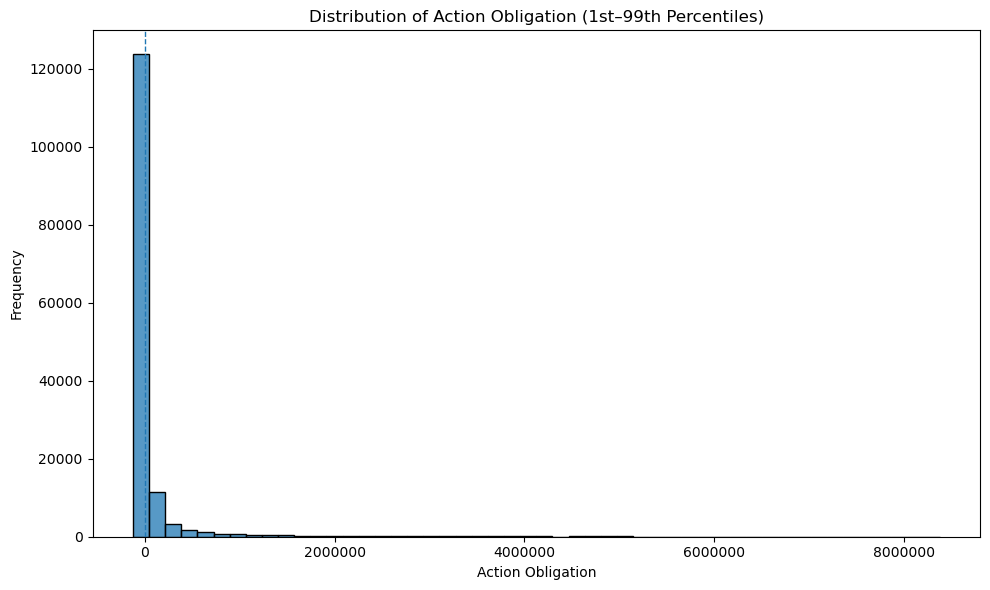

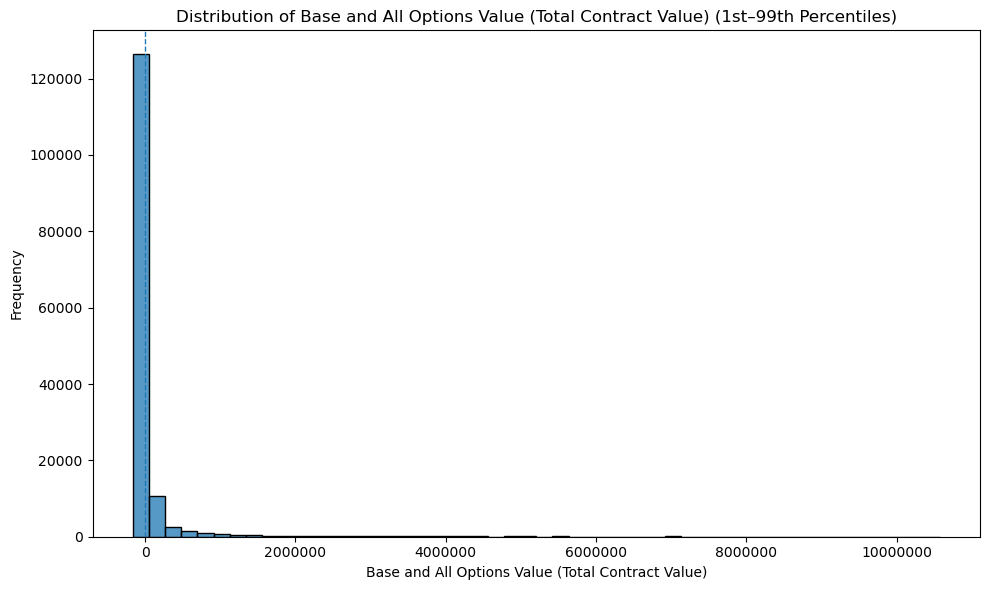

In [72]:
# Histogram: 1-99th percentile - Extreme tails trimmed, negative values retained in the central distribution

for column in numeric_variables:
    lower_limit = eda_data[column].quantile(0.01)
    upper_limit = eda_data[column].quantile(0.99)

    plot_data = eda_data[
        eda_data[column].between(lower_limit, upper_limit)
    ][column]

    plt.figure(figsize=(10, 6))

    sns.histplot(
        plot_data,
        bins=50,
        kde=False
    )

    plt.axvline(
        0,
        linestyle='--',
        linewidth=1
    )

    plt.title(f'Distribution of {column} (1st–99th Percentiles)')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.ticklabel_format(style='plain', axis='x')

    plt.tight_layout()
    plt.show()

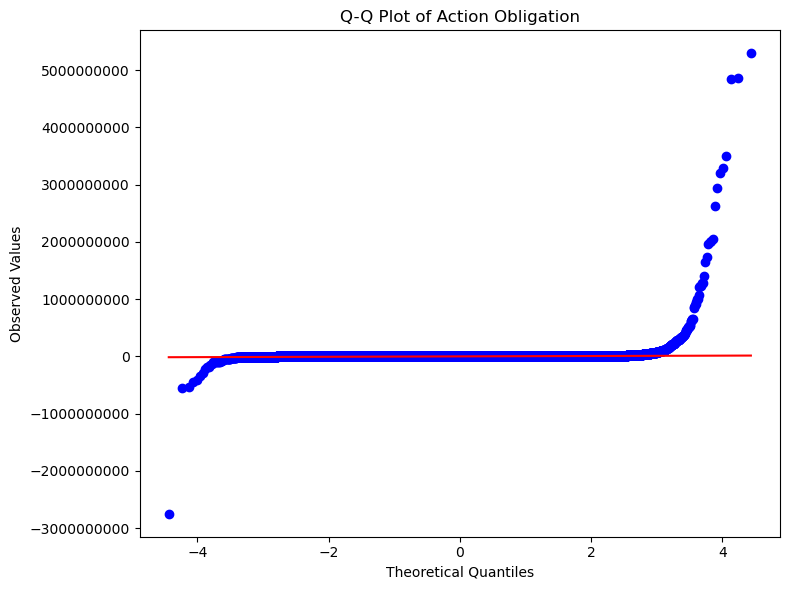

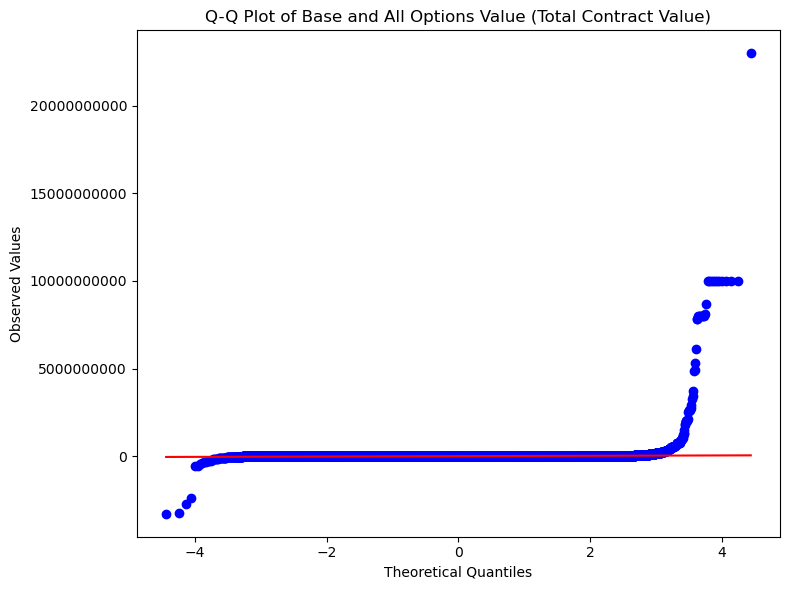

In [73]:
# Q-Q plots

for column in numeric_variables:
    plot_data = eda_data[column].dropna()

    plt.figure(figsize=(8, 6))

    stats.probplot(
        plot_data,
        dist="norm",
        plot=plt
    )

    plt.title(f'Q-Q Plot of {column}')
    plt.xlabel('Theoretical Quantiles')
    plt.ylabel('Observed Values')

    plt.ticklabel_format(style='plain', axis='y')

    plt.tight_layout()
    plt.show()

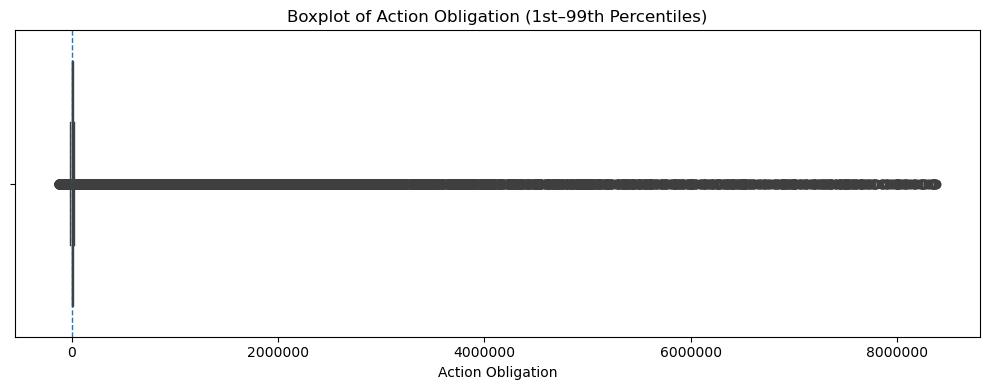

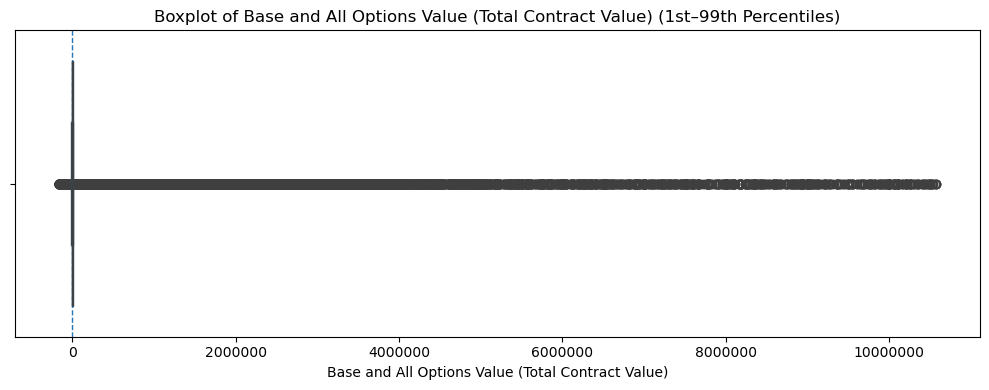

In [74]:
# Boxplots using 1st-99th percentile

for column in numeric_variables:
    lower_limit = eda_data[column].quantile(0.01)
    upper_limit = eda_data[column].quantile(0.99)

    plot_data = eda_data.loc[
        eda_data[column].between(lower_limit, upper_limit),
        column
    ]

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=plot_data
    )

    plt.axvline(
        0,
        linestyle='--',
        linewidth=1
    )

    plt.title(f'Boxplot of {column} (1st–99th Percentiles)')
    plt.xlabel(column)
    plt.ticklabel_format(style='plain', axis='x')

    plt.tight_layout()
    plt.show()

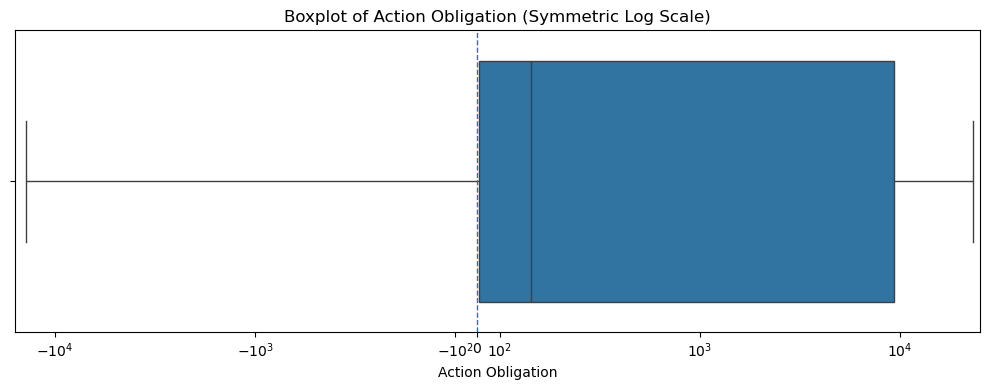

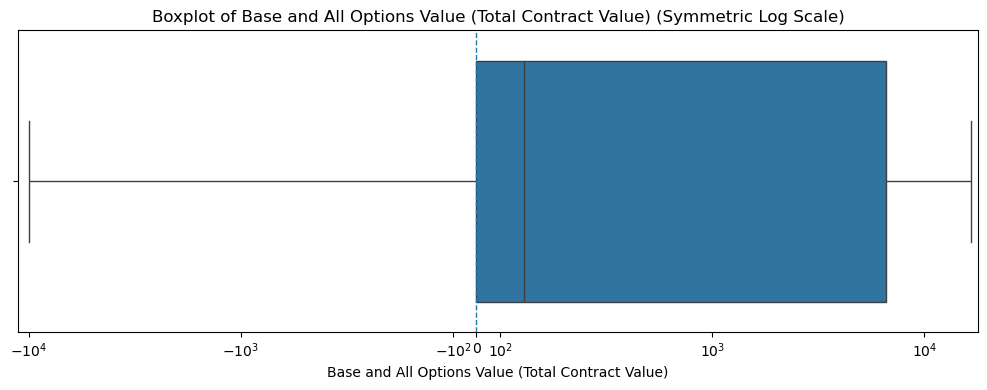

In [75]:
# Symmetric-log boxplots 

for column in numeric_variables:
    plot_data = eda_data[column].dropna()

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=plot_data,
        showfliers=False
    )

    plt.xscale(
        'symlog',
        linthresh=1000
    )

    plt.axvline(
        0,
        linestyle='--',
        linewidth=1
    )

    plt.title(f'Boxplot of {column} (Symmetric Log Scale)')
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

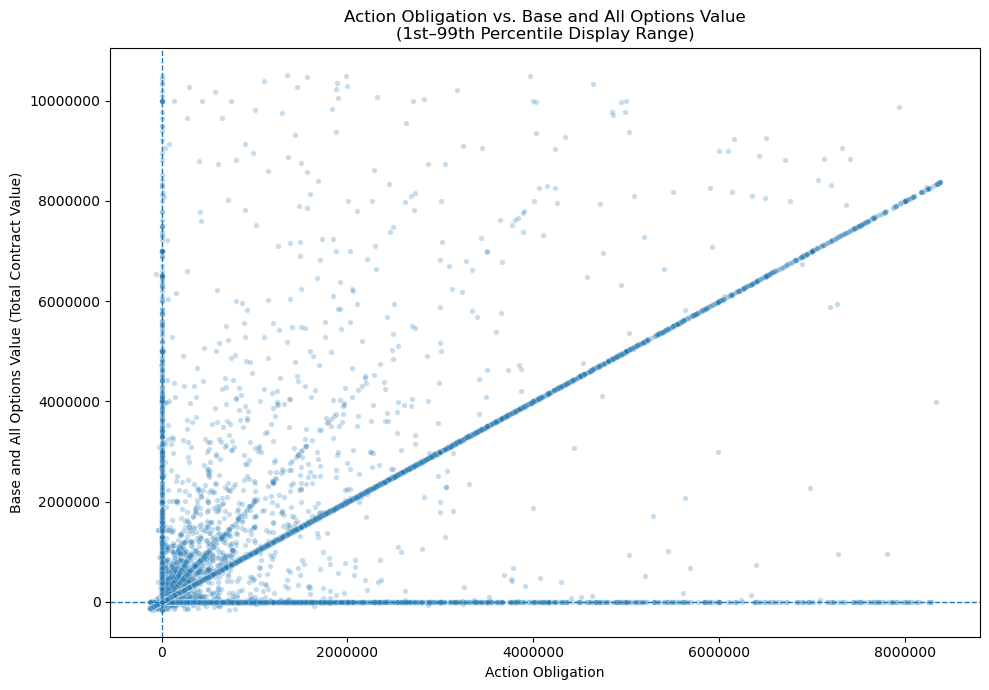

In [76]:
# Scatterplot of Action Obligation and Base and All Options Value (Total Contract Value), restricting each axis to respective 1st-99th percentile range

x_var = 'Action Obligation'
y_var = 'Base and All Options Value (Total Contract Value)'

x_lower = eda_data[x_var].quantile(0.01)
x_upper = eda_data[x_var].quantile(0.99)

y_lower = eda_data[y_var].quantile(0.01)
y_upper = eda_data[y_var].quantile(0.99)

scatter_data = eda_data[
    eda_data[x_var].between(x_lower, x_upper) &
    eda_data[y_var].between(y_lower, y_upper)
]

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=scatter_data,
    x=x_var,
    y=y_var,
    alpha=0.25,
    s=15
)

plt.axhline(0, linestyle='--', linewidth=1)
plt.axvline(0, linestyle='--', linewidth=1)

plt.title(
    'Action Obligation vs. Base and All Options Value\n'
    '(1st–99th Percentile Display Range)'
)

plt.xlabel('Action Obligation')
plt.ylabel('Base and All Options Value (Total Contract Value)')

plt.ticklabel_format(style='plain', axis='both')

plt.tight_layout()
plt.show()

In [77]:
# Correlation 

from scipy.stats import pearsonr, spearmanr

x_var = 'Action Obligation'
y_var = 'Base and All Options Value (Total Contract Value)'

correlation_data = eda_data[[x_var, y_var]].dropna()

pearson_r, pearson_p = pearsonr(
    correlation_data[x_var],
    correlation_data[y_var]
)

spearman_rho, spearman_p = spearmanr(
    correlation_data[x_var],
    correlation_data[y_var]
)

print("Pearson Correlation")
print(f"r = {pearson_r:.4f}")
print(f"p-value = {pearson_p:.4e}")

print("\nSpearman Correlation")
print(f"rho = {spearman_rho:.4f}")
print(f"p-value = {spearman_p:.4e}")

Pearson Correlation
r = 0.3537
p-value = 0.0000e+00

Spearman Correlation
rho = 0.8520
p-value = 0.0000e+00


In [78]:
# Temporal variables 

# Confirm variable type
## Showed that not all observations are correct class

for column in date_variables:
    print(f"\n{'=' * 70}")
    print(column)
    print(f"{'=' * 70}")

    print("Pandas dtype:", eda_data[column].dtype)

    print("\nPython value types:")
    print(eda_data[column].map(type).value_counts())

    print("\nNon-missing:", eda_data[column].notna().sum())
    print("Missing:", eda_data[column].isna().sum())

    print("\nFirst 10 non-missing values:")
    print(eda_data[column].dropna().head(10).tolist())


Completion Date
Pandas dtype: object

Python value types:
Completion Date
<class 'str'>      144712
<class 'float'>      5288
Name: count, dtype: int64

Non-missing: 144712
Missing: 5288

First 10 non-missing values:
['12/31/2020', '12/31/2020', '5/30/2020', '6/30/2020', '9/2/2021', '4/2/2020', '4/8/2020', '4/21/2020', '4/28/2020', '5/6/2020']

Date Signed
Pandas dtype: object

Python value types:
Date Signed
<class 'str'>    150000
Name: count, dtype: int64

Non-missing: 150000
Missing: 0

First 10 non-missing values:
['4/13/2020', '7/1/2020', '4/22/2020', '9/21/2020', '9/2/2020', '4/2/2020', '4/8/2020', '4/21/2020', '4/28/2020', '5/6/2020']

Period of Performance Start Date
Pandas dtype: object

Python value types:
Period of Performance Start Date
<class 'str'>      149997
<class 'float'>         3
Name: count, dtype: int64

Non-missing: 149997
Missing: 3

First 10 non-missing values:
['12/31/2019', '7/1/2020', '6/3/2019', '6/3/2019', '9/2/2020', '4/2/2020', '4/8/2020', '4/21/2020',

In [79]:
# Make backup

date_data_original = eda_data[date_variables].copy()

In [80]:
# Convert date variables

for column in date_variables:
    eda_data[column] = pd.to_datetime(
        eda_data[column],
        format='%m/%d/%Y',
        errors='coerce'
    )

In [81]:
# Validate conversion

for column in date_variables:
    print(f"\n{'=' * 70}")
    print(column)
    print(f"{'=' * 70}")

    original_nonmissing = date_data_original[column].notna().sum()
    converted_nonmissing = eda_data[column].notna().sum()

    original_missing = date_data_original[column].isna().sum()
    converted_missing = eda_data[column].isna().sum()

    print("Data type:", eda_data[column].dtype)
    print(f"Original non-missing:  {original_nonmissing:,}")
    print(f"Converted non-missing: {converted_nonmissing:,}")
    print(f"Original missing:       {original_missing:,}")
    print(f"Converted missing:      {converted_missing:,}")
    print(f"New missing values:     {converted_missing - original_missing:,}")

    print("Minimum date:", eda_data[column].min())
    print("Maximum date:", eda_data[column].max())


Completion Date
Data type: datetime64[ns]
Original non-missing:  144,712
Converted non-missing: 144,706
Original missing:       5,288
Converted missing:      5,294
New missing values:     6
Minimum date: 2008-12-31 00:00:00
Maximum date: 2109-05-31 00:00:00

Date Signed
Data type: datetime64[ns]
Original non-missing:  150,000
Converted non-missing: 150,000
Original missing:       0
Converted missing:      0
New missing values:     0
Minimum date: 2020-03-13 00:00:00
Maximum date: 2023-05-23 00:00:00

Period of Performance Start Date
Data type: datetime64[ns]
Original non-missing:  149,997
Converted non-missing: 149,997
Original missing:       3
Converted missing:      3
New missing values:     0
Minimum date: 1981-01-25 00:00:00
Maximum date: 2024-01-31 00:00:00

Solicitation Date
Data type: datetime64[ns]
Original non-missing:  63,162
Converted non-missing: 63,162
Original missing:       86,838
Converted missing:      86,838
New missing values:     0
Minimum date: 2000-07-16 00:00:00

In [82]:
failed_completion_dates = date_data_original.loc[
    date_data_original['Completion Date'].notna() &
    eda_data['Completion Date'].isna(),
    'Completion Date'
]

print("Failed Completion Date values:")
print(failed_completion_dates)

print("\nUnique failed values:")
print(failed_completion_dates.unique())

Failed Completion Date values:
87378    9/29/9019
87379    9/29/9019
87380    9/29/9019
87381    9/29/9019
87382    9/29/9019
87383    9/29/9019
Name: Completion Date, dtype: object

Unique failed values:
['9/29/9019']


In [83]:
for column in date_variables:
    print(f"\n{'=' * 70}")
    print(column)
    print(f"{'=' * 70}")

    year_counts = (
        eda_data[column]
        .dropna()
        .dt.year
        .value_counts()
        .sort_index()
    )

    print(year_counts.to_string())


Completion Date
Completion Date
2008        1
2013        1
2014        2
2015        6
2016        4
2017       14
2018       37
2019      245
2020    78419
2021    42225
2022    19074
2023     3014
2024      691
2025      603
2026      230
2027       33
2028       20
2029       18
2030        8
2031       17
2032       11
2033        4
2034        5
2035        1
2036        1
2037        2
2039        5
2042        1
2049        2
2055       10
2109        2

Date Signed
Date Signed
2020    93694
2021    40547
2022    15758
2023        1

Period of Performance Start Date
Period of Performance Start Date
1981       10
1993        2
1999        1
2000       15
2001        1
2002        4
2003       33
2004        4
2005        2
2006       39
2007       56
2008       61
2009       25
2010       62
2011      116
2012      101
2013      201
2014      309
2015     1073
2016     1838
2017     2878
2018     4810
2019     8115
2020    91269
2021    30026
2022     8941
2023        4
2024   

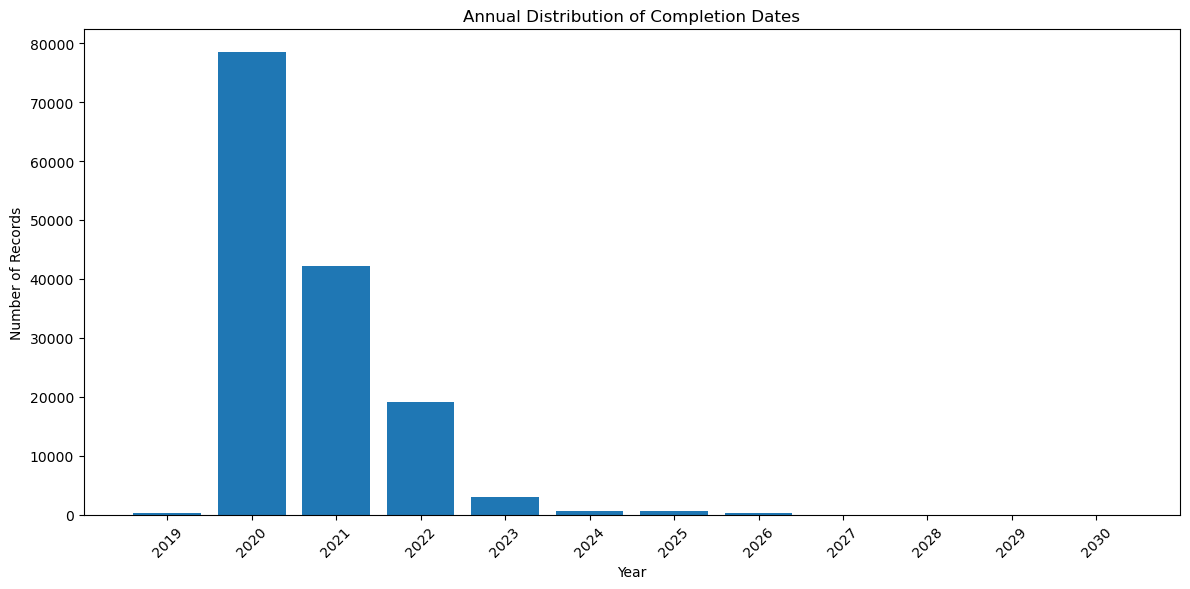

In [84]:
# Annual Distribution Bar Chart for Completion Date

completion_yearly = (
    eda_data['Completion Date']
    .dropna()
    .dt.year
    .value_counts()
    .sort_index()
)

completion_display = completion_yearly.loc[
    (completion_yearly.index >= 2019) &
    (completion_yearly.index <= 2030)
]

plt.figure(figsize=(12, 6))

plt.bar(
    completion_display.index,
    completion_display.values
)

plt.title('Annual Distribution of Completion Dates')
plt.xlabel('Year')
plt.ylabel('Number of Records')

plt.xticks(completion_display.index, rotation=45)

plt.tight_layout()
plt.show()

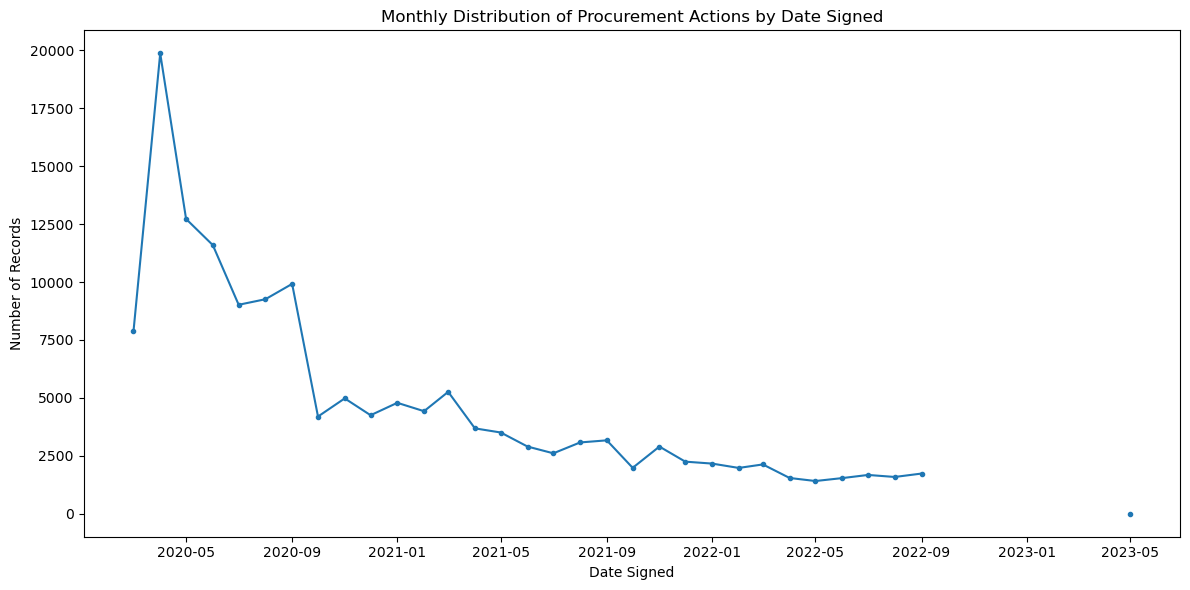

In [85]:
# Time series plot for Date Signed 

monthly_signed = (
    eda_data['Date Signed']
    .dropna()
    .dt.to_period('M')
    .value_counts()
    .sort_index()
)

# Create complete monthly sequence
all_months = pd.period_range(
    start=monthly_signed.index.min(),
    end=monthly_signed.index.max(),
    freq='M'
)

# Add absent months as NaN rather than zero
monthly_signed_plot = monthly_signed.reindex(all_months)

# Convert PeriodIndex to timestamps
monthly_signed_plot.index = monthly_signed_plot.index.to_timestamp()

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_signed_plot.index,
    monthly_signed_plot.values,
    marker='o',
    markersize=3
)

plt.title('Monthly Distribution of Procurement Actions by Date Signed')
plt.xlabel('Date Signed')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.show()

In [86]:
print(monthly_signed.to_string())

Date Signed
2020-03     7875
2020-04    19873
2020-05    12724
2020-06    11596
2020-07     9020
2020-08     9259
2020-09     9921
2020-10     4195
2020-11     4979
2020-12     4252
2021-01     4788
2021-02     4426
2021-03     5261
2021-04     3685
2021-05     3506
2021-06     2900
2021-07     2608
2021-08     3077
2021-09     3168
2021-10     1981
2021-11     2899
2021-12     2248
2022-01     2165
2022-02     1977
2022-03     2128
2022-04     1543
2022-05     1412
2022-06     1538
2022-07     1674
2022-08     1587
2022-09     1734
2023-05        1
Freq: M


In [87]:
# Examine high volume of 2004 values in Solicitation Date

solicitation_2004 = eda_data.loc[
    eda_data['Solicitation Date'].dt.year == 2004,
    'Solicitation Date'
]

print("Number of 2004 Solicitation Dates:")
print(len(solicitation_2004))

print("\nMost common 2004 Solicitation Dates:")
print(
    solicitation_2004
    .value_counts()
    .head(20)
)

Number of 2004 Solicitation Dates:
5347

Most common 2004 Solicitation Dates:
Solicitation Date
2004-03-15    5347
Name: count, dtype: int64


In [88]:
solicitation_2004_rows = eda_data[
    eda_data['Solicitation Date'] == '2004-03-15'
]

print(f"Total rows: {len(solicitation_2004_rows):,}")

variables_to_check = [
    'Contracting Office Name',
    'Funding Department Name',
    'NAICS Code',
    'Product or Service Code',
    'Description of Requirement'
]

for column in variables_to_check:
    print(f"\n{'=' * 70}")
    print(column)
    print(f"{'=' * 70}")
    print(f"Unique values: {solicitation_2004_rows[column].nunique(dropna=True):,}")
    print("\nMost common values:")
    print(
        solicitation_2004_rows[column]
        .value_counts(dropna=False)
        .head(10)
    )

Total rows: 5,347

Contracting Office Name
Unique values: 1

Most common values:
Contracting Office Name
GSA/FAS SCIENTFC,TEMP SVCS,ADINT    5347
Name: count, dtype: int64

Funding Department Name
Unique values: 1

Most common values:
Funding Department Name
GENERAL SERVICES ADMINISTRATION    5347
Name: count, dtype: int64

NAICS Code
Unique values: 1

Most common values:
NAICS Code
333319    5347
Name: count, dtype: int64

Product or Service Code
Unique values: 1

Most common values:
Product or Service Code
7910    5347
Name: count, dtype: int64

Description of Requirement
Unique values: 165

Most common values:
Description of Requirement
GLOVES,DISPOSABLE,NITRILE:AMBIDEXTROUS,POWDER-FREE,LATEX-FREE,INDUSTRIAL GRADE,NITRILE GLOVES FOR GENERAL PURPOSE USE. NITRILE SHALL BE SOFT FORMULATION ALLOWS GLOVES TO CONFORM TO HAND. 4 MILS THICK MIN. SIZE LARGE, 9 1/2" . U/I BX (100 EA         1105
GLOVES,DISPOSABLE,NITRILE:AMBIDEXTROUS,POWDER- FREE,LATEX-FREE,INDUSTRIAL GRADE,NITRILE GLOVES FOR

In [89]:
print(
    solicitation_2004_rows['Date Signed']
    .dt.year
    .value_counts()
    .sort_index()
)

Date Signed
2020    4374
2021     973
Name: count, dtype: int64


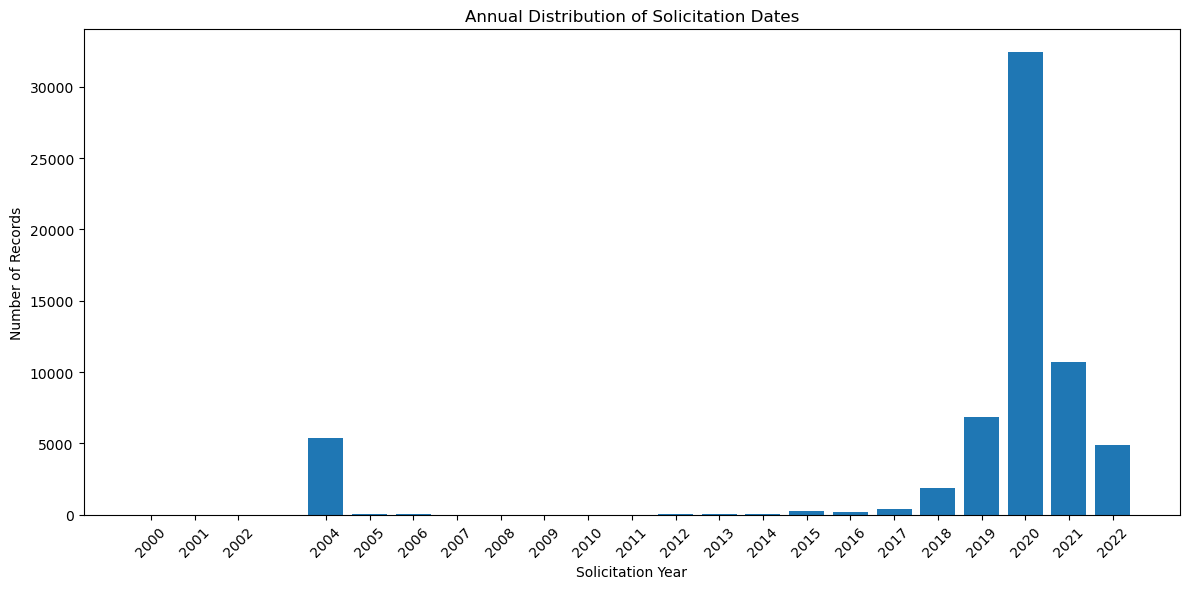

In [90]:
# Annual Distribution Bar chart for Solicitation Date

solicitation_yearly = (
    eda_data['Solicitation Date']
    .dropna()
    .dt.year
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.bar(
    solicitation_yearly.index,
    solicitation_yearly.values
)

plt.title('Annual Distribution of Solicitation Dates')
plt.xlabel('Solicitation Year')
plt.ylabel('Number of Records')

plt.xticks(solicitation_yearly.index, rotation=45)

plt.tight_layout()
plt.show()

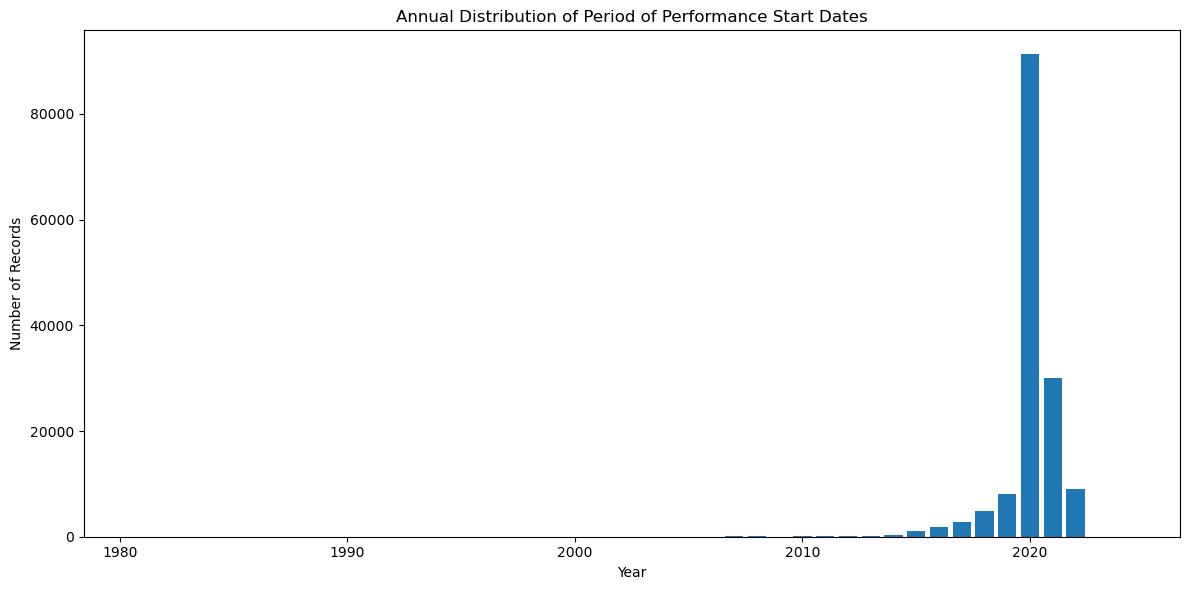

In [91]:
# Annual Distribution Bar Chart for Period of Performance Start Date

performance_yearly = (
    eda_data['Period of Performance Start Date']
    .dropna()
    .dt.year
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.bar(
    performance_yearly.index,
    performance_yearly.values
)

plt.title('Annual Distribution of Period of Performance Start Dates')
plt.xlabel('Year')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.show()

In [92]:
# Examine contract performance duration 

performance_duration = (
    eda_data['Completion Date'] -
    eda_data['Period of Performance Start Date']
).dt.days

print("Performance Duration (days)")
print("=" * 70)
print(f"Valid durations:    {performance_duration.notna().sum():,}")
print(f"Missing durations:  {performance_duration.isna().sum():,}")
print(f"Negative durations: {(performance_duration < 0).sum():,}")
print(f"Zero durations:     {(performance_duration == 0).sum():,}")
print(f"Positive durations: {(performance_duration > 0).sum():,}")

print("\nDescriptive statistics:")
print(
    performance_duration
    .describe(percentiles=[.01, .05, .25, .50, .75, .95, .99])
)

Performance Duration (days)
Valid durations:    144,703
Missing durations:  5,297
Negative durations: 20
Zero durations:     11,469
Positive durations: 133,214

Descriptive statistics:
count    144703.000000
mean        244.303055
std         569.627948
min        -393.000000
1%            0.000000
5%            0.000000
25%           6.000000
50%          30.000000
75%         243.000000
95%        1324.000000
99%        2039.000000
max       33237.000000
dtype: float64


In [93]:
# Examine negative POPs

negative_duration_rows = eda_data.loc[
    performance_duration < 0,
    [
        'Period of Performance Start Date',
        'Completion Date',
        'Date Signed',
        'Solicitation Date',
        'Contracting Office Name',
        'Description of Requirement'
    ]
].copy()

negative_duration_rows['Performance Duration (Days)'] = (
    negative_duration_rows['Completion Date'] -
    negative_duration_rows['Period of Performance Start Date']
).dt.days

print(
    negative_duration_rows
    .sort_values('Performance Duration (Days)')
    .to_string(index=False)
)

Period of Performance Start Date Completion Date Date Signed Solicitation Date                 Contracting Office Name                                                                                                                                                                                                                            Description of Requirement  Performance Duration (Days)
                      2022-01-28      2020-12-31  2020-05-07        2019-07-12  248-NETWORK CONTRACT OFFICE 8 (36C248)                                                                                                                                                                                                 SUSPENSION OF WORK - RENOVATE 10AB MENTAL HEALTH WARD                         -393
                      2021-11-16      2021-06-01  2021-04-09        2020-10-27  248-NETWORK CONTRACT OFFICE 8 (36C248)                                                                                              

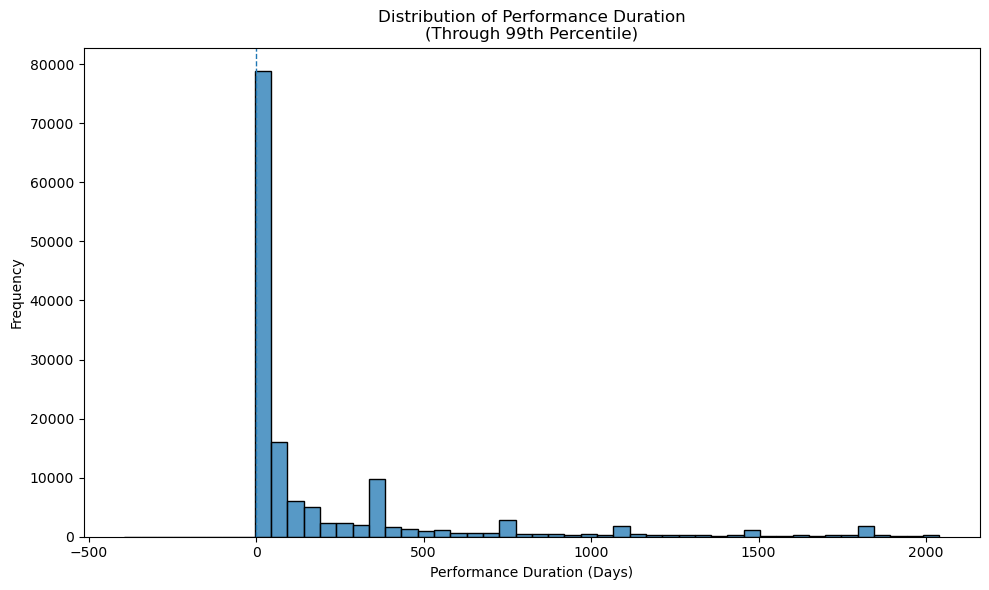

In [94]:
# Histogram of 1st-99th percentile of Performance Duration 

upper = performance_duration.quantile(0.99)

performance_plot = performance_duration[
    performance_duration <= upper
].dropna()

plt.figure(figsize=(10, 6))

sns.histplot(
    performance_plot,
    bins=50,
    kde=False
)

plt.axvline(0, linestyle='--', linewidth=1)

plt.title(
    'Distribution of Performance Duration\n'
    '(Through 99th Percentile)'
)
plt.xlabel('Performance Duration (Days)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [95]:
# Examine Solicitation-to-Signing Interval

solicitation_to_signed = (
    eda_data['Date Signed'] -
    eda_data['Solicitation Date']
).dt.days

print("Solicitation-to-Signing Interval (days)")
print("=" * 70)
print(f"Valid intervals:    {solicitation_to_signed.notna().sum():,}")
print(f"Missing intervals:  {solicitation_to_signed.isna().sum():,}")
print(f"Negative intervals: {(solicitation_to_signed < 0).sum():,}")
print(f"Zero intervals:     {(solicitation_to_signed == 0).sum():,}")
print(f"Positive intervals: {(solicitation_to_signed > 0).sum():,}")

print("\nDescriptive statistics:")
print(
    solicitation_to_signed
    .describe(percentiles=[.01, .05, .25, .50, .75, .95, .99])
)

Solicitation-to-Signing Interval (days)
Valid intervals:    63,162
Missing intervals:  86,838
Negative intervals: 0
Zero intervals:     20,366
Positive intervals: 42,796

Descriptive statistics:
count    63162.000000
mean       686.569599
std       1647.383436
min          0.000000
1%           0.000000
5%           0.000000
25%          0.000000
50%         60.000000
75%        402.000000
95%       5884.000000
99%       6198.000000
max       7913.000000
dtype: float64


In [96]:
cluster_mask = (
    eda_data['Solicitation Date'] == pd.Timestamp('2004-03-15')
)

cluster_intervals = solicitation_to_signed[cluster_mask]
other_intervals = solicitation_to_signed[
    solicitation_to_signed.notna() & ~cluster_mask
]

print("March 15, 2004 solicitation cluster")
print("=" * 70)
print(f"Records: {len(cluster_intervals):,}")
print(cluster_intervals.describe())

print("\nAll other solicitation records")
print("=" * 70)
print(f"Records: {len(other_intervals):,}")
print(
    other_intervals.describe(
        percentiles=[.01, .05, .25, .50, .75, .95, .99]
    )
)

March 15, 2004 solicitation cluster
Records: 5,347
count    5347.000000
mean     5974.781934
std       135.374631
min      5844.000000
25%      5869.000000
50%      5898.000000
75%      6044.000000
max      6500.000000
dtype: float64

All other solicitation records
Records: 57,815
count    57815.000000
mean       197.491136
std        370.912460
min          0.000000
1%           0.000000
5%           0.000000
25%          0.000000
50%         34.000000
75%        278.500000
95%        802.000000
99%       1636.860000
max       7913.000000
dtype: float64


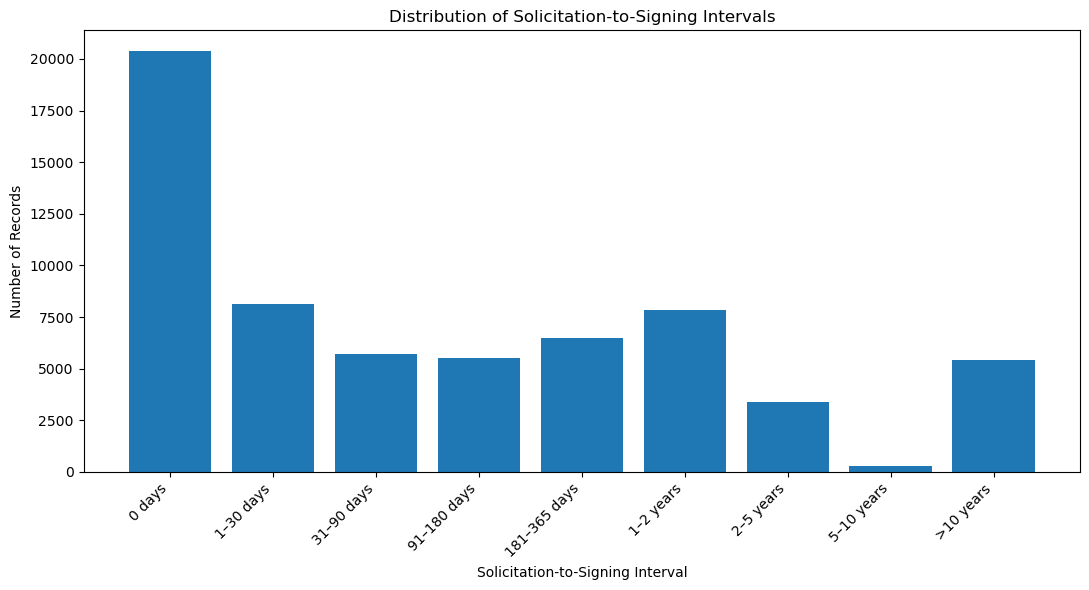

              Frequency  Percent
0 days            20366    32.24
1–30 days          8154    12.91
31–90 days         5711     9.04
91–180 days        5510     8.72
181–365 days       6501    10.29
1–2 years          7822    12.38
2–5 years          3377     5.35
5–10 years          296     0.47
>10 years          5425     8.59


In [97]:
# Binned Frequency Distribution of Solicitation-to-Signing Interval

interval_bins = [
    0,
    1,
    31,
    91,
    181,
    366,
    731,
    1826,
    3651,
    np.inf
]

interval_labels = [
    '0 days',
    '1–30 days',
    '31–90 days',
    '91–180 days',
    '181–365 days',
    '1–2 years',
    '2–5 years',
    '5–10 years',
    '>10 years'
]

interval_categories = pd.cut(
    solicitation_to_signed.dropna(),
    bins=interval_bins,
    labels=interval_labels,
    right=False
)

interval_counts = (
    interval_categories
    .value_counts()
    .reindex(interval_labels)
)

plt.figure(figsize=(11, 6))

plt.bar(
    interval_counts.index,
    interval_counts.values
)

plt.title('Distribution of Solicitation-to-Signing Intervals')
plt.xlabel('Solicitation-to-Signing Interval')
plt.ylabel('Number of Records')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

interval_summary = pd.DataFrame({
    'Frequency': interval_counts,
    'Percent': (interval_counts / interval_counts.sum()) * 100
})

print(interval_summary.round(2))

In [98]:
# Categorical variables

In [99]:
# Diagnositc summary

categorical_summary = []

for column in categorical_variables:
    
    total = len(eda_data)
    missing = eda_data[column].isna().sum()
    nonmissing = eda_data[column].notna().sum()
    unique = eda_data[column].nunique(dropna=True)

    counts = eda_data[column].value_counts(dropna=True)

    if len(counts) > 0:
        most_common = counts.index[0]
        most_common_count = counts.iloc[0]
        most_common_percent = (most_common_count / nonmissing) * 100
    else:
        most_common = None
        most_common_count = 0
        most_common_percent = np.nan

    categorical_summary.append({
        'Variable': column,
        'Non-Missing': nonmissing,
        'Missing': missing,
        'Missing %': (missing / total) * 100,
        'Unique Categories': unique,
        'Most Common Category': most_common,
        'Most Common Count': most_common_count,
        'Most Common %': most_common_percent
    })

categorical_summary = pd.DataFrame(categorical_summary)

pd.set_option('display.max_colwidth', 100)

print(
    categorical_summary
    .round({
        'Missing %': 2,
        'Most Common %': 2
    })
    .to_string(index=False)
)

                                         Variable  Non-Missing  Missing  Missing %  Unique Categories             Most Common Category  Most Common Count  Most Common %
             Other Than Full and Open Competition       150000        0       0.00                 18                          Missing             115196          76.80
                 Fair Opportunity/Limited Sources       150000        0       0.00                  9                          Missing             107795          71.86
                                Type of Set Aside       150000        0       0.00                 19                          Missing             100038          66.69
                       Domestic or Foreign Entity       144927     5073       3.38                  5              U.S. OWNED BUSINESS             138678          95.69
                        Vendor Address State Name       148114     1886       1.26                 56                         VIRGINIA              23540  

In [100]:
# Inspect category frequencies

for column in categorical_variables:
    print(f"\n{'=' * 80}")
    print(column)
    print(f"{'=' * 80}")

    counts = eda_data[column].value_counts(dropna=False)

    print(f"Unique non-missing categories: {eda_data[column].nunique(dropna=True):,}")
    print(f"Missing observations: {eda_data[column].isna().sum():,}")

    print("\nTop 10 categories:")
    print(counts.head(10).to_string())


Other Than Full and Open Competition
Unique non-missing categories: 18
Missing observations: 0

Top 10 categories:
Other Than Full and Open Competition
Missing                                               115196
AUTHORIZED BY STATUTE (FAR 6.302-5(A)(2)(I))           13696
URGENCY (FAR 6.302-2)                                   7817
SAP NON-COMPETITION (FAR 13)                            7155
ONLY ONE SOURCE-OTHER (FAR 6.302-1 OTHER)               4118
LESS THAN OR EQUAL TO THE MICRO-PURCHASE THRESHOLD       472
MOBILIZATION, ESSENTIAL R&D (FAR 6.302-3)                323
BRAND NAME DESCRIPTION (FAR 6.302-1(C))                  320
UNIQUE SOURCE (FAR 6.302-1(B)(1))                        299
FOLLOW-ON CONTRACT (FAR 6.302-1(A)(2)(II/III))           201

Fair Opportunity/Limited Sources
Unique non-missing categories: 9
Missing observations: 0

Top 10 categories:
Fair Opportunity/Limited Sources
Missing                                                  107795
FAIR OPPORTUNITY GIVEN       

In [101]:
# Bar charts for categorical variables

def plot_categorical_distribution(
    data,
    column,
    top_n=None,
    include_other=False,
    figsize=(10, 6)
):
    counts = data[column].value_counts(dropna=False)

    if top_n is not None and len(counts) > top_n:

        top_counts = counts.head(top_n)

        if include_other:
            other_count = counts.iloc[top_n:].sum()
            counts = pd.concat([
                top_counts,
                pd.Series({'Other': other_count})
            ])
        else:
            counts = top_counts

    # Sort categories by frequency
    plot_counts = counts.sort_values()

    # If Other exists, keep it at the bottom of the displayed chart
    if 'Other' in plot_counts.index:
        other_value = plot_counts.loc['Other']
        plot_counts = plot_counts.drop('Other')
        plot_counts = pd.concat([
            pd.Series({'Other': other_value}),
            plot_counts
        ])

    plt.figure(figsize=figsize)

    plt.barh(
        plot_counts.index.astype(str),
        plot_counts.values
    )

    plt.title(f'Distribution of {column}')
    plt.xlabel('Number of Records')
    plt.ylabel(column)

    plt.tight_layout()
    plt.show()

    summary = pd.DataFrame({
        'Frequency': counts,
        'Percent': (counts / len(data)) * 100
    })

    print(f"\n{column}")
    print(summary.round(2).to_string())

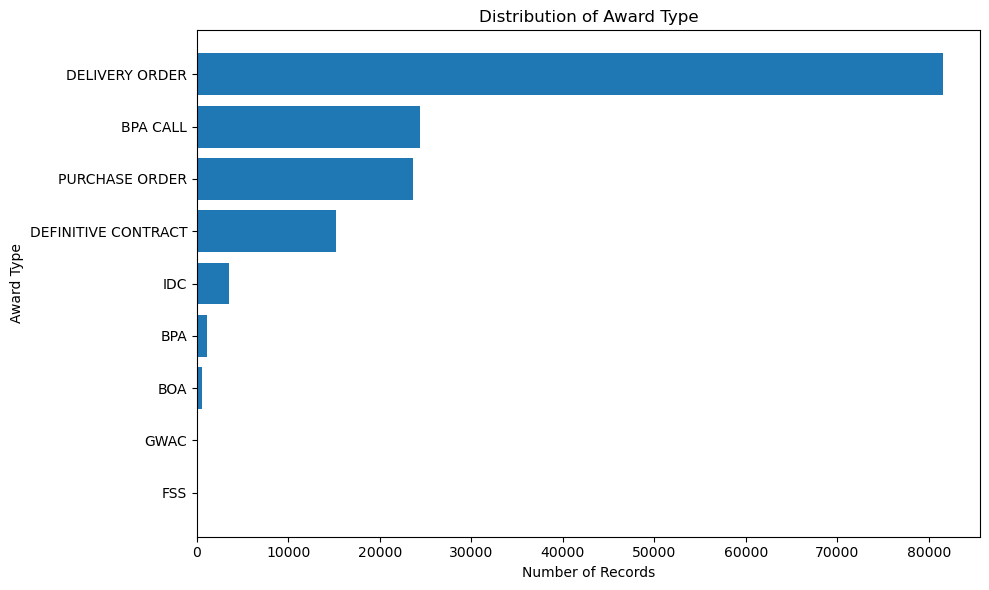


Award Type
                     Frequency  Percent
Award Type                             
DELIVERY ORDER           81500    54.33
BPA CALL                 24410    16.27
PURCHASE ORDER           23617    15.74
DEFINITIVE CONTRACT      15185    10.12
IDC                       3562     2.37
BPA                       1153     0.77
BOA                        564     0.38
GWAC                         8     0.01
FSS                          1     0.00


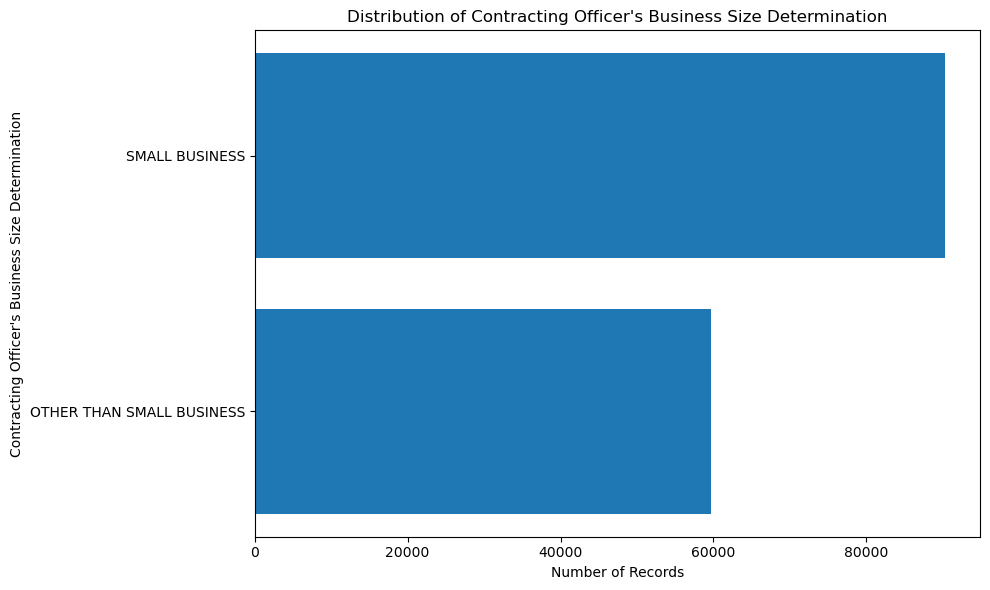


Contracting Officer's Business Size Determination
                                                   Frequency  Percent
Contracting Officer's Business Size Determination                    
SMALL BUSINESS                                         90345    60.23
OTHER THAN SMALL BUSINESS                              59655    39.77


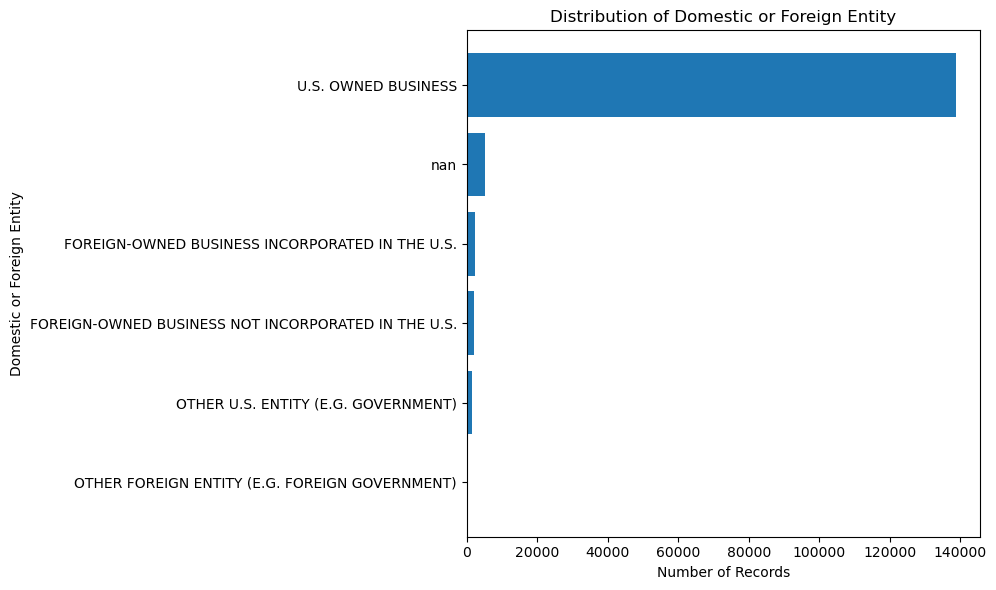


Domestic or Foreign Entity
                                                     Frequency  Percent
Domestic or Foreign Entity                                             
U.S. OWNED BUSINESS                                     138678    92.45
NaN                                                       5073     3.38
FOREIGN-OWNED BUSINESS INCORPORATED IN THE U.S.           2359     1.57
FOREIGN-OWNED BUSINESS NOT INCORPORATED IN THE U.S.       2192     1.46
OTHER U.S. ENTITY (E.G. GOVERNMENT)                       1449     0.97
OTHER FOREIGN ENTITY (E.G. FOREIGN GOVERNMENT)             249     0.17


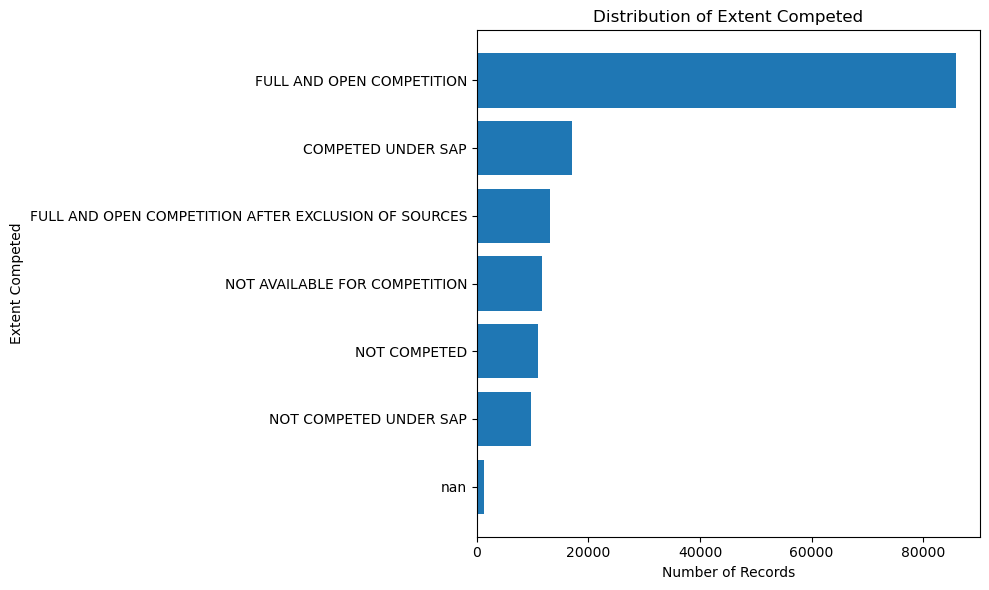


Extent Competed
                                                      Frequency  Percent
Extent Competed                                                         
FULL AND OPEN COMPETITION                                 85868    57.25
COMPETED UNDER SAP                                        17045    11.36
FULL AND OPEN COMPETITION AFTER EXCLUSION OF SOURCES      13121     8.75
NOT AVAILABLE FOR COMPETITION                             11750     7.83
NOT COMPETED                                              11054     7.37
NOT COMPETED UNDER SAP                                     9792     6.53
NaN                                                        1370     0.91


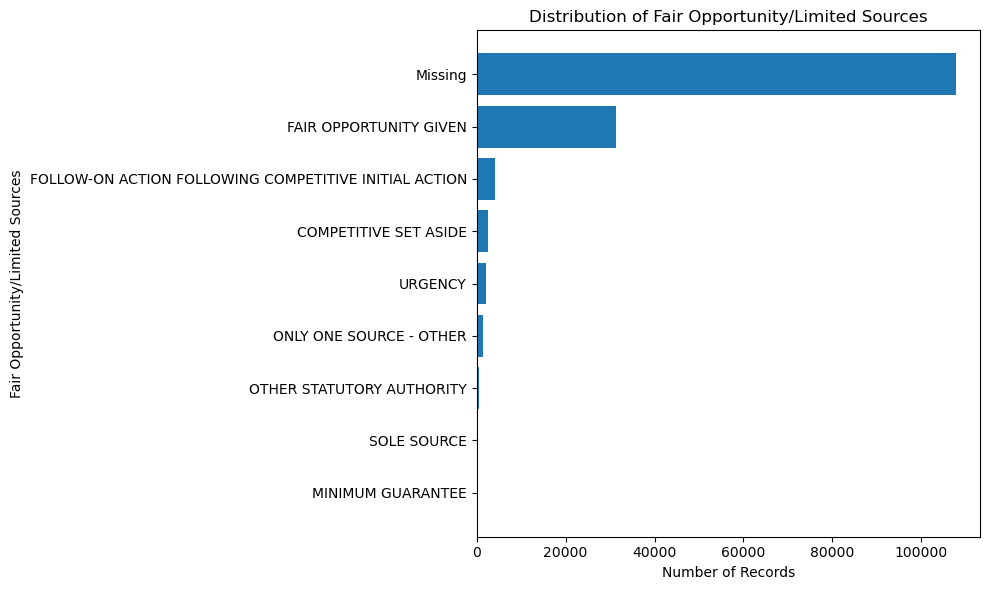


Fair Opportunity/Limited Sources
                                                       Frequency  Percent
Fair Opportunity/Limited Sources                                         
Missing                                                   107795    71.86
FAIR OPPORTUNITY GIVEN                                     31348    20.90
FOLLOW-ON ACTION FOLLOWING COMPETITIVE INITIAL ACTION       4135     2.76
COMPETITIVE SET ASIDE                                       2456     1.64
URGENCY                                                     2172     1.45
ONLY ONE SOURCE - OTHER                                     1414     0.94
OTHER STATUTORY AUTHORITY                                    470     0.31
SOLE SOURCE                                                  140     0.09
MINIMUM GUARANTEE                                             70     0.05


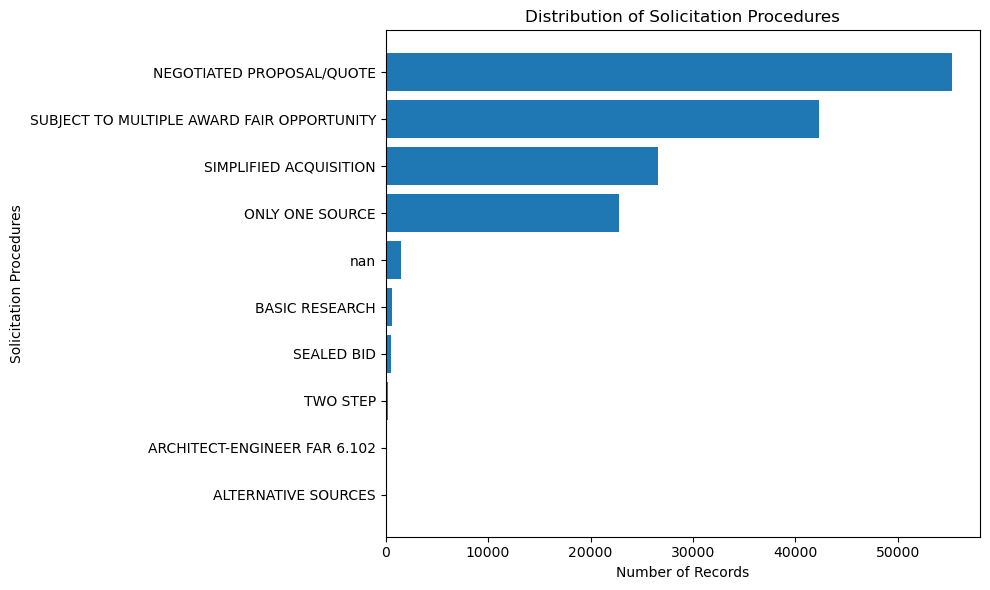


Solicitation Procedures
                                            Frequency  Percent
Solicitation Procedures                                       
NEGOTIATED PROPOSAL/QUOTE                       55257    36.84
SUBJECT TO MULTIPLE AWARD FAIR OPPORTUNITY      42261    28.17
SIMPLIFIED ACQUISITION                          26580    17.72
ONLY ONE SOURCE                                 22791    15.19
NaN                                              1450     0.97
BASIC RESEARCH                                    618     0.41
SEALED BID                                        532     0.35
TWO STEP                                          228     0.15
ARCHITECT-ENGINEER FAR 6.102                      158     0.11
ALTERNATIVE SOURCES                               125     0.08


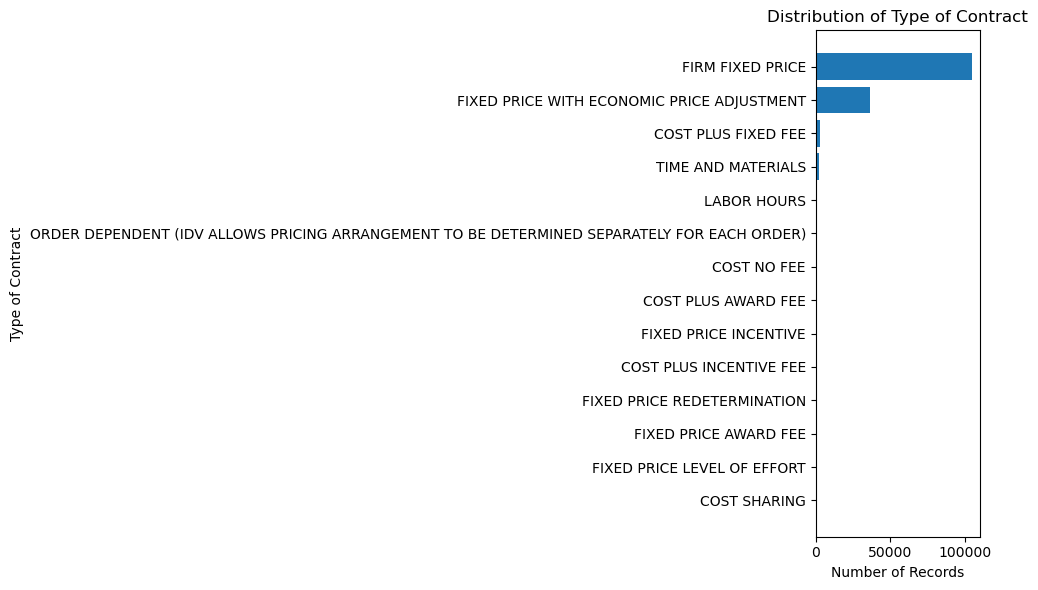


Type of Contract
                                                                                             Frequency  Percent
Type of Contract                                                                                               
FIRM FIXED PRICE                                                                                104653    69.77
FIXED PRICE WITH ECONOMIC PRICE ADJUSTMENT                                                       36470    24.31
COST PLUS FIXED FEE                                                                               2908     1.94
TIME AND MATERIALS                                                                                1970     1.31
LABOR HOURS                                                                                       1194     0.80
ORDER DEPENDENT (IDV ALLOWS PRICING ARRANGEMENT TO BE DETERMINED SEPARATELY FOR EACH ORDER)        841     0.56
COST NO FEE                                                                           

In [102]:
# Low-cardinality variables - all categories shown

plot_categorical_distribution(
    eda_data,
    "Award Type"
)

plot_categorical_distribution(
    eda_data,
    "Contracting Officer's Business Size Determination"
)

plot_categorical_distribution(
    eda_data,
    'Domestic or Foreign Entity'
)

plot_categorical_distribution(
    eda_data,
    'Extent Competed'
)

plot_categorical_distribution(
    eda_data,
    'Fair Opportunity/Limited Sources'
)

plot_categorical_distribution(
    eda_data,
    'Solicitation Procedures'
)

plot_categorical_distribution(
    eda_data,
    'Type of Contract'
)

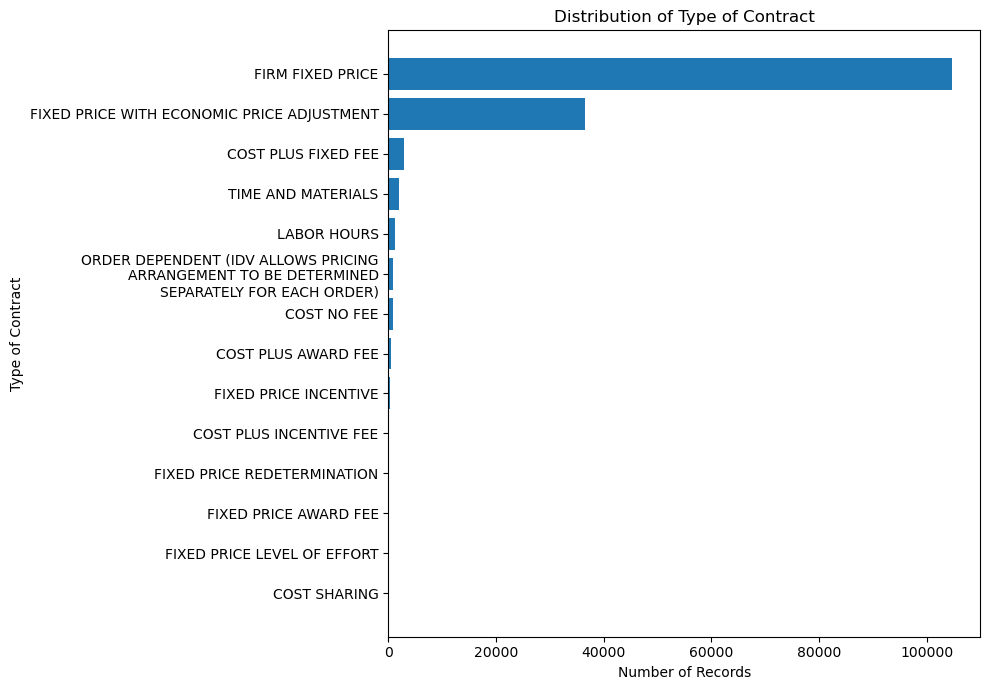

In [103]:
# Custom plot to improve readability of Type of Contract

contract_counts = (
    eda_data['Type of Contract']
    .value_counts(dropna=False)
    .sort_values()
)

# Create display labels 
display_labels = []

for label in contract_counts.index.astype(str):

    if label == (
        'ORDER DEPENDENT (IDV ALLOWS PRICING ARRANGEMENT '
        'TO BE DETERMINED SEPARATELY FOR EACH ORDER)'
    ):
        label = (
            'ORDER DEPENDENT (IDV ALLOWS PRICING\n'
            'ARRANGEMENT TO BE DETERMINED\n'
            'SEPARATELY FOR EACH ORDER)'
        )

    display_labels.append(label)

plt.figure(figsize=(10, 7))

plt.barh(
    display_labels,
    contract_counts.values
)

plt.title('Distribution of Type of Contract')
plt.xlabel('Number of Records')
plt.ylabel('Type of Contract')

plt.tight_layout()
plt.show()

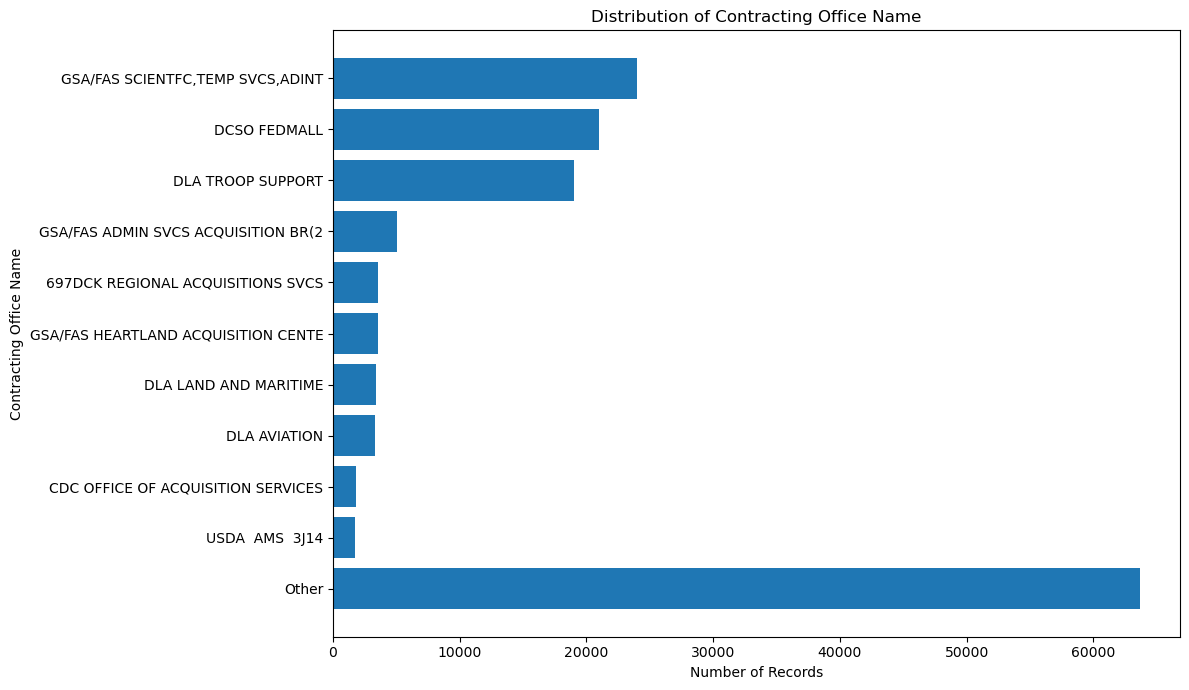


Contracting Office Name
                                     Frequency  Percent
GSA/FAS SCIENTFC,TEMP SVCS,ADINT         23982    15.99
DCSO FEDMALL                             20977    13.98
DLA TROOP SUPPORT                        19049    12.70
GSA/FAS ADMIN SVCS ACQUISITION BR(2       5085     3.39
697DCK REGIONAL ACQUISITIONS SVCS         3563     2.38
GSA/FAS HEARTLAND ACQUISITION CENTE       3528     2.35
DLA LAND AND MARITIME                     3360     2.24
DLA AVIATION                              3274     2.18
CDC OFFICE OF ACQUISITION SERVICES        1795     1.20
USDA  AMS  3J14                           1733     1.16
Other                                    63654    42.44


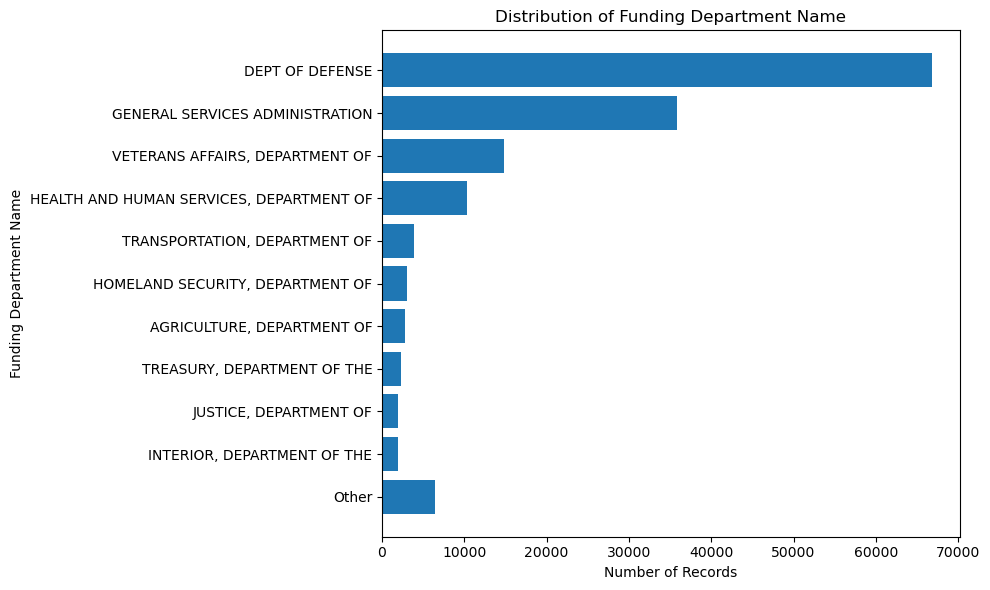


Funding Department Name
                                          Frequency  Percent
DEPT OF DEFENSE                               66814    44.54
GENERAL SERVICES ADMINISTRATION               35875    23.92
VETERANS AFFAIRS, DEPARTMENT OF               14817     9.88
HEALTH AND HUMAN SERVICES, DEPARTMENT OF      10345     6.90
TRANSPORTATION, DEPARTMENT OF                  3867     2.58
HOMELAND SECURITY, DEPARTMENT OF               2995     2.00
AGRICULTURE, DEPARTMENT OF                     2731     1.82
TREASURY, DEPARTMENT OF THE                    2315     1.54
JUSTICE, DEPARTMENT OF                         1969     1.31
INTERIOR, DEPARTMENT OF THE                    1896     1.26
Other                                          6376     4.25


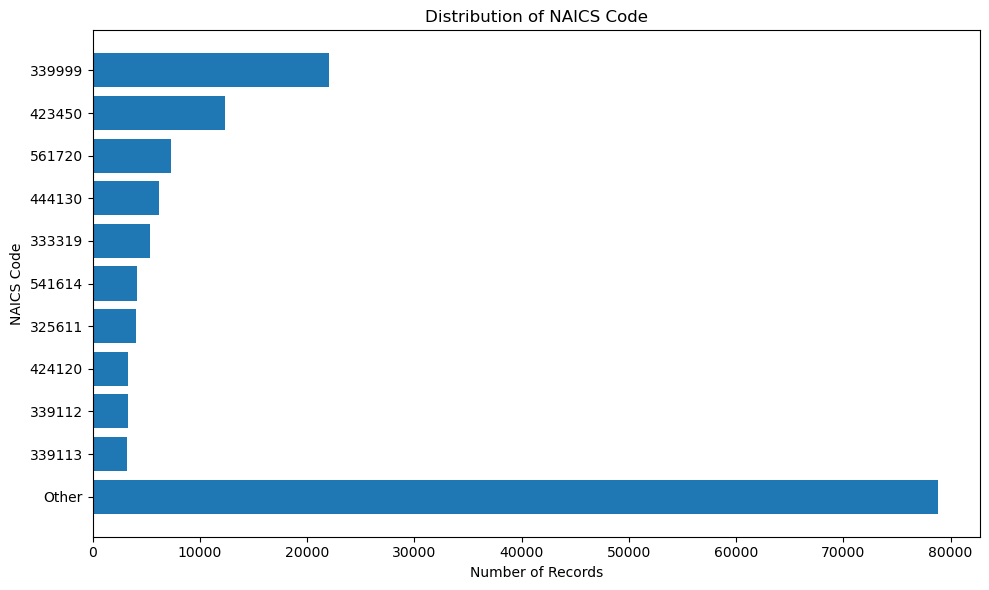


NAICS Code
        Frequency  Percent
339999      22055    14.70
423450      12362     8.24
561720       7302     4.87
444130       6191     4.13
333319       5366     3.58
541614       4118     2.75
325611       4017     2.68
424120       3334     2.22
339112       3279     2.19
339113       3179     2.12
Other       78797    52.53


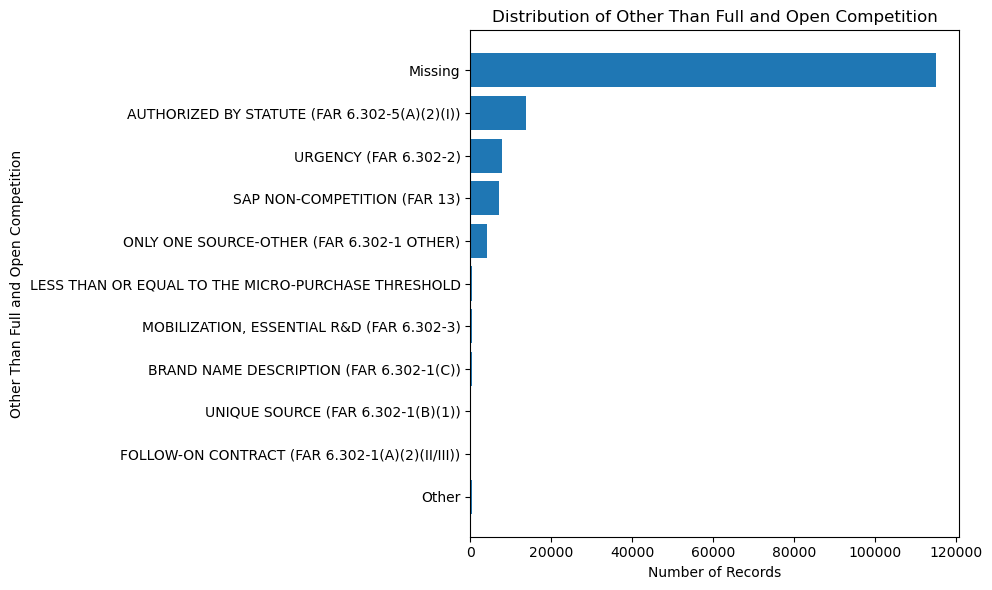


Other Than Full and Open Competition
                                                    Frequency  Percent
Missing                                                115196    76.80
AUTHORIZED BY STATUTE (FAR 6.302-5(A)(2)(I))            13696     9.13
URGENCY (FAR 6.302-2)                                    7817     5.21
SAP NON-COMPETITION (FAR 13)                             7155     4.77
ONLY ONE SOURCE-OTHER (FAR 6.302-1 OTHER)                4118     2.75
LESS THAN OR EQUAL TO THE MICRO-PURCHASE THRESHOLD        472     0.31
MOBILIZATION, ESSENTIAL R&D (FAR 6.302-3)                 323     0.22
BRAND NAME DESCRIPTION (FAR 6.302-1(C))                   320     0.21
UNIQUE SOURCE (FAR 6.302-1(B)(1))                         299     0.20
FOLLOW-ON CONTRACT (FAR 6.302-1(A)(2)(II/III))            201     0.13
Other                                                     403     0.27


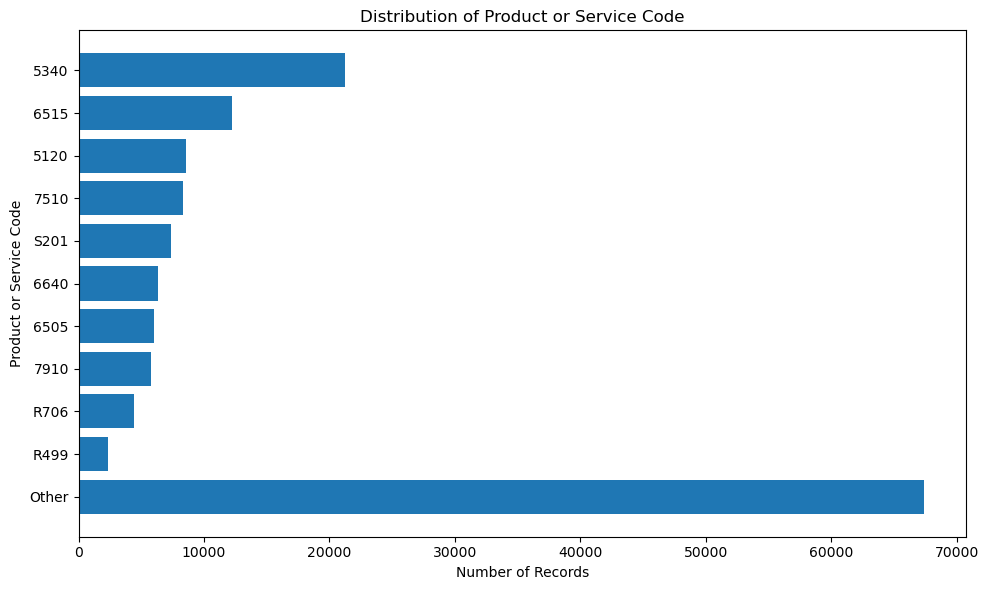


Product or Service Code
       Frequency  Percent
5340       21273    14.18
6515       12207     8.14
5120        8564     5.71
7510        8322     5.55
S201        7360     4.91
6640        6336     4.22
6505        6021     4.01
7910        5744     3.83
R706        4404     2.94
R499        2364     1.58
Other      67405    44.94


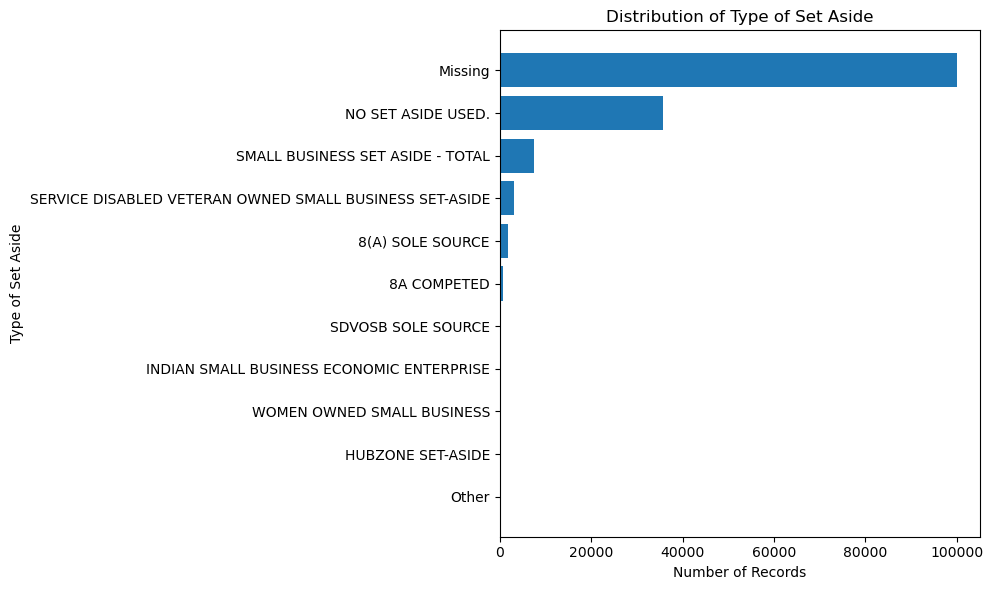


Type of Set Aside
                                                         Frequency  Percent
Missing                                                     100038    66.69
NO SET ASIDE USED.                                           35731    23.82
SMALL BUSINESS SET ASIDE - TOTAL                              7511     5.01
SERVICE DISABLED VETERAN OWNED SMALL BUSINESS SET-ASIDE       3039     2.03
8(A) SOLE SOURCE                                              1746     1.16
8A COMPETED                                                    642     0.43
SDVOSB SOLE SOURCE                                             388     0.26
INDIAN SMALL BUSINESS ECONOMIC ENTERPRISE                      336     0.22
WOMEN OWNED SMALL BUSINESS                                     166     0.11
HUBZONE SET-ASIDE                                              136     0.09
Other                                                          267     0.18


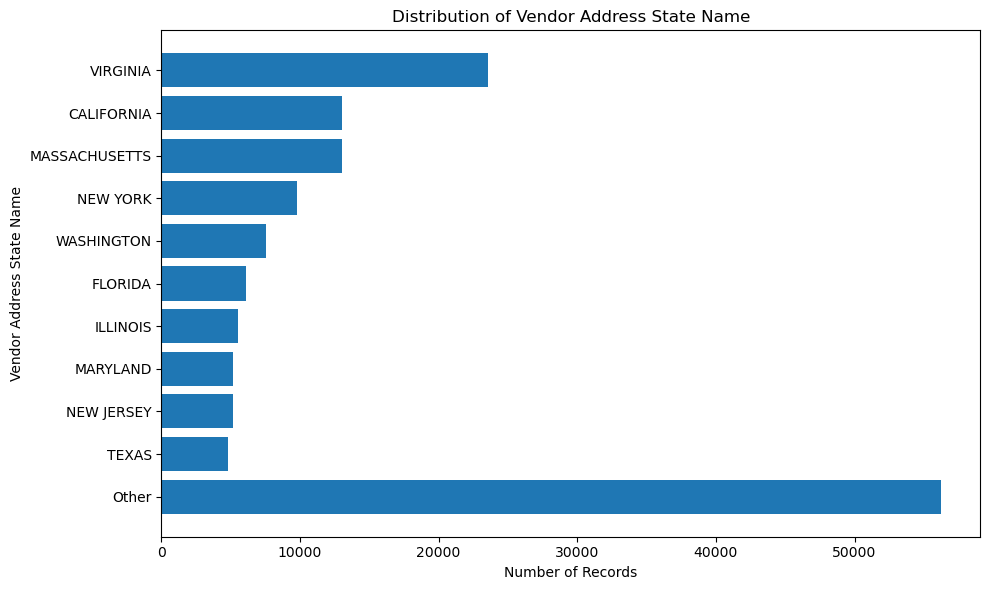


Vendor Address State Name
               Frequency  Percent
VIRGINIA           23540    15.69
CALIFORNIA         13015     8.68
MASSACHUSETTS      13009     8.67
NEW YORK            9786     6.52
WASHINGTON          7556     5.04
FLORIDA             6074     4.05
ILLINOIS            5548     3.70
MARYLAND            5198     3.47
NEW JERSEY          5195     3.46
TEXAS               4840     3.23
Other              56239    37.49


In [104]:
# Medium- and high-cardinality variables - top-10

plot_categorical_distribution(
    eda_data,
    'Contracting Office Name',
    top_n=10,
    include_other=True,
    figsize=(12, 7)
)

plot_categorical_distribution(
    eda_data,
    'Funding Department Name',
    top_n=10,
    include_other=True
)

plot_categorical_distribution(
    eda_data,
    'NAICS Code',
    top_n=10,
    include_other=True
)

plot_categorical_distribution(
    eda_data,
    'Other Than Full and Open Competition',
    top_n=10,
    include_other=True
)

plot_categorical_distribution(
    eda_data,
    'Product or Service Code',
    top_n=10,
    include_other=True
)

plot_categorical_distribution(
    eda_data,
    'Type of Set Aside',
    top_n=10,
    include_other=True
)

plot_categorical_distribution(
    eda_data,
    'Vendor Address State Name',
    top_n=10,
    include_other=True
)

In [105]:
# Text variables 

In [106]:
# Diagnostic summary of text variables

text_summary = []

for column in text_variables:
    series = eda_data[column]

    # Treat actual NaN separately
    missing = series.isna().sum()
    nonmissing = series.notna().sum()

    # Work only with non-missing strings
    text = series.dropna().astype(str).str.strip()

    empty = (text == '').sum()
    unique = text.nunique()

    char_length = text.str.len()
    word_count = text.str.split().str.len()

    text_summary.append({
        'Variable': column,
        'Non-Missing': nonmissing,
        'Missing': missing,
        'Missing %': (missing / len(series)) * 100,
        'Empty Strings': empty,
        'Unique Texts': unique,
        'Unique %': (unique / nonmissing) * 100 if nonmissing else 0,
        'Median Characters': char_length.median(),
        'Mean Characters': char_length.mean(),
        'Median Words': word_count.median(),
        'Mean Words': word_count.mean(),
        'Max Words': word_count.max()
    })

text_summary = pd.DataFrame(text_summary)

print(
    text_summary
    .round(2)
    .to_string(index=False)
)

                      Variable  Non-Missing  Missing  Missing %  Empty Strings  Unique Texts  Unique %  Median Characters  Mean Characters  Median Words  Mean Words  Max Words
    Description of Requirement       149978       22       0.01              0         94422     62.96               45.0            78.87           6.0       10.73        564
Product or Service Description       150000        0       0.00              0          1419      0.95               33.0            36.59           4.0        4.20         17


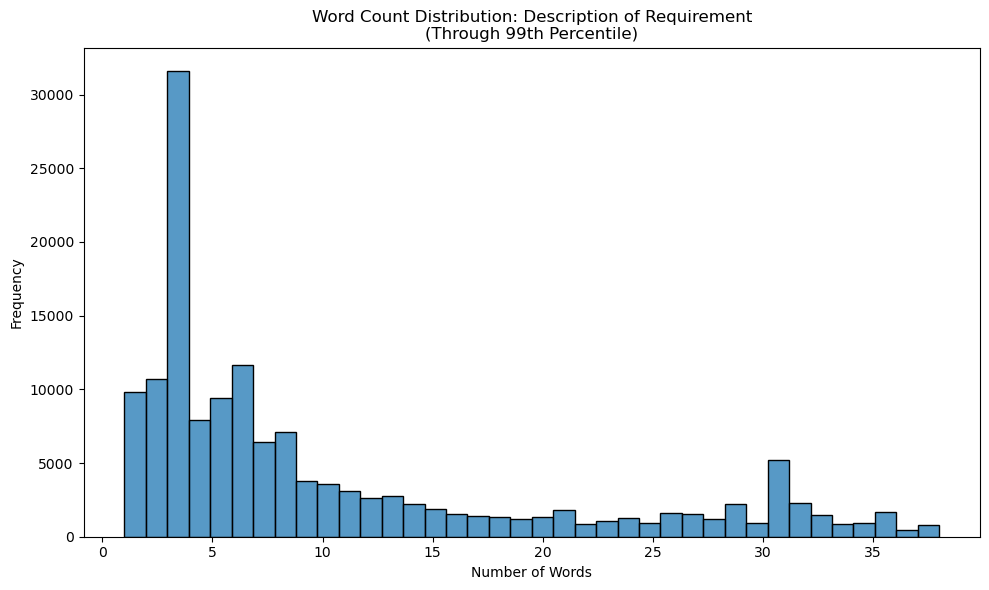

In [107]:
# Word count distribution for Description of Requirement

requirement_words = (
    eda_data['Description of Requirement']
    .dropna()
    .astype(str)
    .str.strip()
    .str.split()
    .str.len()
)

upper = requirement_words.quantile(0.99)

requirement_plot = requirement_words[
    requirement_words <= upper
]

plt.figure(figsize=(10, 6))

sns.histplot(
    requirement_plot,
    bins=38,
    kde=False
)

plt.title(
    'Word Count Distribution: Description of Requirement\n'
    '(Through 99th Percentile)'
)
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [108]:
# Word count descriptive statistics

for column in text_variables:

    word_counts = (
        eda_data[column]
        .dropna()
        .astype(str)
        .str.strip()
        .str.split()
        .str.len()
    )

    print(f"\n{'=' * 70}")
    print(column)
    print(f"{'=' * 70}")

    print(
        word_counts.describe(
            percentiles=[
                .01, .05, .25, .50, .75, .95, .99
            ]
        )
    )


Description of Requirement
count    149978.000000
mean         10.734154
std          12.273577
min           1.000000
1%            1.000000
5%            1.000000
25%           3.000000
50%           6.000000
75%          14.000000
95%          33.000000
99%          38.000000
max         564.000000
Name: Description of Requirement, dtype: float64

Product or Service Description
count    150000.000000
mean          4.204093
std           2.126873
min           1.000000
1%            2.000000
5%            2.000000
25%           2.000000
50%           4.000000
75%           6.000000
95%           8.000000
99%          11.000000
max          17.000000
Name: Product or Service Description, dtype: float64


In [109]:
# Frequent repeated text

for column in text_variables:

    counts = (
        eda_data[column]
        .dropna()
        .astype(str)
        .str.strip()
        .value_counts()
    )

    print(f"\n{'=' * 80}")
    print(column)
    print(f"{'=' * 80}")

    print(f"Unique text values: {len(counts):,}")
    print("\nMost frequent exact text values:")
    print(counts.head(15).to_string())


Description of Requirement
Unique text values: 94,422

Most frequent exact text values:
Description of Requirement
GLOVES,DISPOSABLE,NITRILE:AMBIDEXTROUS,POWDER- FREE,LATEX-FREE,INDUSTRIAL GRADE,NITRILE GLOVES FOR GENERAL PURPOSE USE. NITRILE SHALL BE SOFT FORMULATION ALLOWS GLOVES TO CONFORM TO HAND. 4 MILS THICK, MIN. MEDIUM, 9 1/2 IN, DISPENSER BOX. U/I B    1927
GLOVES,DISPOSABLE,NITRILE:AMBIDEXTROUS,POWDER-FREE,LATEX-FREE,INDUSTRIAL GRADE,NITRILE GLOVES FOR GENERAL PURPOSE USE. NITRILE SHALL BE SOFT FORMULATION ALLOWS GLOVES TO CONFORM TO HAND. 4 MILS THICK MIN. SIZE LARGE, 9 1/2" . U/I BX (100 EA         1755
HAND SANITIZER                                                                                                                                                                                                                                           1119
GLOVES,DISPOSABLE,NITRILE:AMBIDEXTROUS,POWDER- FREE,LATEX-FREE,INDUSTRIAL GRADE,NITRILE GLOVES FOR GENERAL PURPOSE USE. NI

In [110]:
# Top term analysis for Description of Requirement 

from sklearn.feature_extraction.text import CountVectorizer

requirement_text = (
    eda_data['Description of Requirement']
    .dropna()
    .astype(str)
)

vectorizer = CountVectorizer(
    lowercase=True,
    stop_words='english',
    token_pattern=r'(?u)\b[a-zA-Z]{2,}\b'
)

term_matrix = vectorizer.fit_transform(requirement_text)

term_counts = np.asarray(
    term_matrix.sum(axis=0)
).ravel()

terms = vectorizer.get_feature_names_out()

term_frequency = (
    pd.DataFrame({
        'Term': terms,
        'Frequency': term_counts
    })
    .sort_values('Frequency', ascending=False)
)

print(term_frequency.head(30).to_string(index=False))

        Term  Frequency
       covid      32950
         non      25482
      gloves      22866
     nitrile      21163
   materials      20663
         nsn      20166
       emall      20066
        hand      18039
        free      15614
    services      14949
         box      10852
   sanitizer      10412
     purpose      10232
         use       9630
     general       8556
  industrial       8141
     support       8077
  disposable       7670
       latex       7541
         min       7011
       shall       6714
      powder       6596
    cleaning       6353
        size       5927
       large       5905
       grade       5893
modification       5877
        soft       5874
      allows       5749
ambidextrous       5740


In [111]:
# Revised top term analysis for Description of Requirement, adding stop words

from sklearn.feature_extraction.text import (
    CountVectorizer,
    ENGLISH_STOP_WORDS
)

domain_stopwords = {
    'non',
    'nsn',
    'emall',
    'free',
    'box',
    'purpose',
    'use',
    'general',
    'min',
    'shall',
    'size',
    'large',
    'grade',
    'soft',
    'allows'
}

eda_stopwords = list(
    set(ENGLISH_STOP_WORDS).union(domain_stopwords)
)

vectorizer = CountVectorizer(
    lowercase=True,
    stop_words=eda_stopwords,
    token_pattern=r'(?u)\b[a-zA-Z]{2,}\b'
)

term_matrix = vectorizer.fit_transform(
    eda_data['Description of Requirement']
    .dropna()
    .astype(str)
)

term_counts = np.asarray(
    term_matrix.sum(axis=0)
).ravel()

terms = vectorizer.get_feature_names_out()

term_frequency = (
    pd.DataFrame({
        'Term': terms,
        'Frequency': term_counts
    })
    .sort_values(
        'Frequency',
        ascending=False
    )
)

print(term_frequency.head(30).to_string(index=False))

        Term  Frequency
       covid      32950
      gloves      22866
     nitrile      21163
   materials      20663
        hand      18039
    services      14949
   sanitizer      10412
  industrial       8141
     support       8077
  disposable       7670
       latex       7541
      powder       6596
    cleaning       6353
modification       5877
ambidextrous       5740
        mils       5738
     conform       5731
   dispenser       5112
 formulation       4800
disinfectant       4753
       black       4541
       order       4196
     cleaner       4178
      medium       4107
    contract       3974
       talon       3712
  janitorial       3652
       paper       3408
          ea       3167
   emergency       3164


In [112]:
# Bi-gram analysis

from sklearn.feature_extraction.text import CountVectorizer

bigram_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words=eda_stopwords,
    token_pattern=r'(?u)\b[a-zA-Z]{2,}\b',
    ngram_range=(2, 2)
)

bigram_matrix = bigram_vectorizer.fit_transform(
    eda_data['Description of Requirement']
    .dropna()
    .astype(str)
)

bigram_counts = np.asarray(
    bigram_matrix.sum(axis=0)
).ravel()

bigrams = bigram_vectorizer.get_feature_names_out()

bigram_frequency = (
    pd.DataFrame({
        'Bigram': bigrams,
        'Frequency': bigram_counts
    })
    .sort_values(
        'Frequency',
        ascending=False
    )
)

print(bigram_frequency.head(30).to_string(index=False))

              Bigram  Frequency
      hand sanitizer       9522
   gloves disposable       5754
  disposable nitrile       5738
        powder latex       5724
        conform hand       5723
    latex industrial       5723
 ambidextrous powder       5723
           hand mils       5723
  industrial nitrile       5723
nitrile ambidextrous       5723
      nitrile gloves       4985
      gloves nitrile       4868
 nitrile formulation       4783
  formulation gloves       4783
      gloves conform       4622
        gloves black       3804
         black talon       3710
       talon nitrile       3703
   attached document       2463
 janitorial services       2432
         trbo region       2355
       ethyl alcohol       2245
        instant hand       2238
           toxic dye       2031
    medium dispenser       1930
         mils medium       1927
   sanitizer instant       1886
    support services       1866
               bx ea       1816
        pump bottles       1797


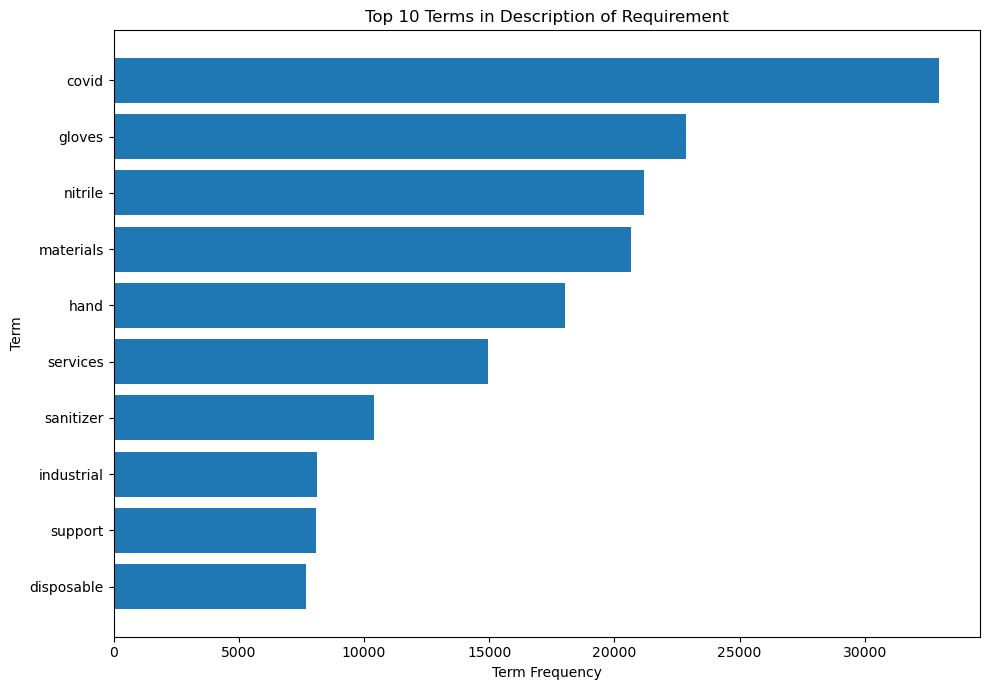

In [242]:
# Bar chart of top 20 terms in Description of Requirement

top_terms = (
    term_frequency
    .head(20)
    .sort_values('Frequency')
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_terms['Term'],
    top_terms['Frequency']
)

plt.title('Top 20 Terms in Description of Requirement')
plt.xlabel('Term Frequency')
plt.ylabel('Term')

plt.tight_layout()
plt.show()

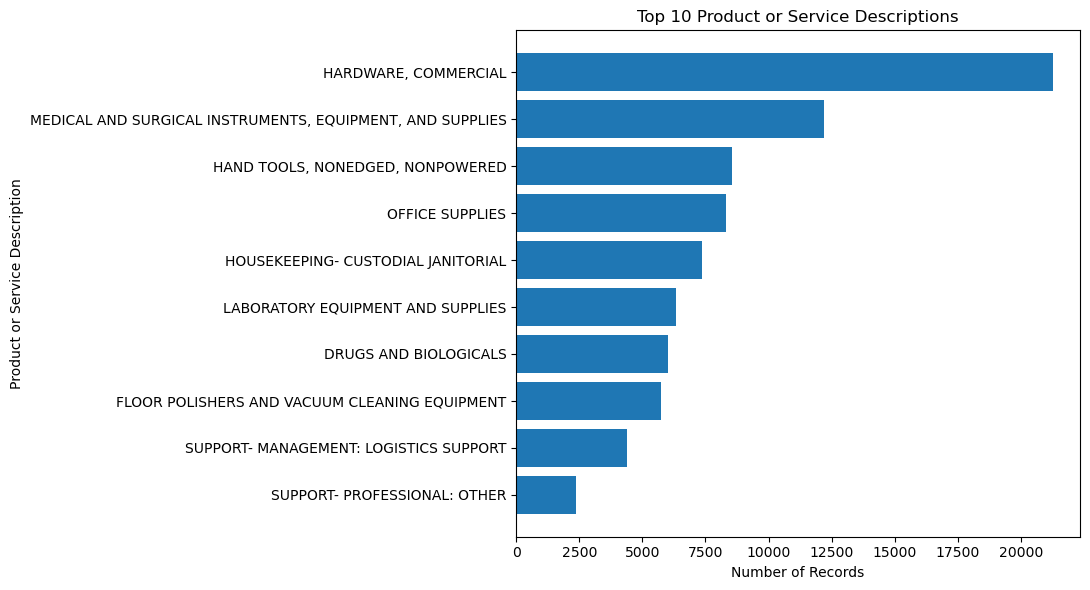

In [114]:
# Frequency bar chart of top terms for Product of Service Description

product_description_counts = (
    eda_data['Product or Service Description']
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(11, 6))

plt.barh(
    product_description_counts.index,
    product_description_counts.values
)

plt.title('Top 10 Product or Service Descriptions')
plt.xlabel('Number of Records')
plt.ylabel('Product or Service Description')

plt.tight_layout()
plt.show()

In [115]:
# Examine relationship between Product or Service Code and Product or Service Description

# Check cardinality

psc_col = 'Product or Service Code'
desc_col = 'Product or Service Description'

print("Product or Service Code")
print(f"Unique values: {eda_data[psc_col].nunique(dropna=False):,}")
print(f"Missing values: {eda_data[psc_col].isna().sum():,}")

print("\nProduct or Service Description")
print(f"Unique values: {eda_data[desc_col].nunique(dropna=False):,}")
print(f"Missing values: {eda_data[desc_col].isna().sum():,}")

Product or Service Code
Unique values: 1,392
Missing values: 0

Product or Service Description
Unique values: 1,419
Missing values: 0


In [116]:
# Determine how many descriptions map to codes

descriptions_per_psc = (
    eda_data
    .groupby(psc_col)[desc_col]
    .nunique()
    .sort_values(ascending=False)
)

print("Number of unique descriptions per PSC:")
print(descriptions_per_psc.value_counts().sort_index())

print(
    "\nPSC codes associated with more than one description:",
    (descriptions_per_psc > 1).sum()
)

print(
    "Maximum descriptions associated with a single PSC:",
    descriptions_per_psc.max()
)

Number of unique descriptions per PSC:
Product or Service Description
1    1359
2      33
Name: count, dtype: int64

PSC codes associated with more than one description: 33
Maximum descriptions associated with a single PSC: 2


In [117]:
# Determine if one description maps to different codes

pscs_per_description = (
    eda_data
    .groupby(desc_col)[psc_col]
    .nunique()
    .sort_values(ascending=False)
)

print("Number of unique PSC codes per description:")
print(pscs_per_description.value_counts().sort_index())

print(
    "\nDescriptions associated with more than one PSC:",
    (pscs_per_description > 1).sum()
)

print(
    "Maximum PSC codes associated with a single description:",
    pscs_per_description.max()
)

Number of unique PSC codes per description:
Product or Service Code
1    1413
2       6
Name: count, dtype: int64

Descriptions associated with more than one PSC: 6
Maximum PSC codes associated with a single description: 2


In [118]:
# Inspect records where one code maps to multiple descriptions

multi_description_pscs = descriptions_per_psc[
    descriptions_per_psc > 1
].index

psc_description_exceptions = (
    eda_data[
        eda_data[psc_col].isin(multi_description_pscs)
    ][[psc_col, desc_col]]
    .drop_duplicates()
    .sort_values([psc_col, desc_col])
)

print(psc_description_exceptions.to_string(index=False))

Product or Service Code                                                                       Product or Service Description
                   5805                                                          NO PRODUCT OR SERVICE DESCRIPTION SPECIFIED
                   5805                                                                    TELEPHONE AND TELEGRAPH EQUIPMENT
                   5895                                                                MISCELLANEOUS COMMUNICATION EQUIPMENT
                   5895                                                          NO PRODUCT OR SERVICE DESCRIPTION SPECIFIED
                   7E20 IT AND TELECOM - END USER: HELP DESK;TIER 1-2, WORKSPACE, PRINT, PRODUCTIVITY TOOL (HW/PERPETUAL SW)
                   7E20 IT AND TELECOM - END USER: HELP DESK;TIER 1-2,WORKSPACE,PRINT,OUTPUT,PRODUCTIVITY TOOLS (HW/PERP SW)
                   AA11                         AGRICULTURE R&D SERVICES; AGRICULTURAL RESEARCH AND SERVICES; BASIC RESEARCH


In [119]:
# # Inspect records where one description maps to multiple codes

multi_psc_descriptions = pscs_per_description[
    pscs_per_description > 1
].index

description_psc_exceptions = (
    eda_data[
        eda_data[desc_col].isin(multi_psc_descriptions)
    ][[desc_col, psc_col]]
    .drop_duplicates()
    .sort_values([desc_col, psc_col])
)

print(description_psc_exceptions.head(100).to_string(index=False))

                         Product or Service Description Product or Service Code
                       LEASE/RENTAL OF OFFICE BUILDINGS                    X111
                       LEASE/RENTAL OF OFFICE BUILDINGS                    X1AA
            NO PRODUCT OR SERVICE DESCRIPTION SPECIFIED                    5805
            NO PRODUCT OR SERVICE DESCRIPTION SPECIFIED                    5895
                          OPERATION OF OFFICE BUILDINGS                    M111
                          OPERATION OF OFFICE BUILDINGS                    M1AA
                               SPACE VEHICLE COMPONENTS                    1675
                               SPACE VEHICLE COMPONENTS                    1820
                                         SPACE VEHICLES                    1555
                                         SPACE VEHICLES                    1810
TRANSPORTATION/TRAVEL/RELOCATION- TRANSPORTATION: OTHER                    V119
TRANSPORTATION/TRAVEL/RELOCATION- TRANSP

In [120]:
# Identify most comment description for each code

pair_counts = (
    eda_data
    .groupby([psc_col, desc_col])
    .size()
    .reset_index(name='Frequency')
)

dominant_description_counts = (
    pair_counts
    .sort_values('Frequency', ascending=False)
    .drop_duplicates(subset=psc_col)
)

records_matching_dominant_mapping = (
    dominant_description_counts['Frequency'].sum()
)

mapping_consistency = (
    records_matching_dominant_mapping / len(eda_data)
) * 100

print(
    f"Records matching the dominant PSC-to-description mapping: "
    f"{records_matching_dominant_mapping:,}"
)

print(
    f"PSC-to-description mapping consistency: "
    f"{mapping_consistency:.4f}%"
)

Records matching the dominant PSC-to-description mapping: 149,384
PSC-to-description mapping consistency: 99.5893%
